# Round 5 Exploration
**50 new products, position limit = 10 each. Previous-round products cannot be traded.**

| Group | Products |
|---|---|
| Galaxy Sounds Recorders | DARK_MATTER, BLACK_HOLES, PLANETARY_RINGS, SOLAR_WINDS, SOLAR_FLAMES |
| Vertical Sleeping Pods | SUEDE, LAMB_WOOL, POLYESTER, NYLON, COTTON |
| Organic Microchips | CIRCLE, OVAL, SQUARE, RECTANGLE, TRIANGLE |
| Purification Pebbles | XS, S, M, L, XL |
| Domestic Robots | VACUUMING, MOPPING, DISHES, LAUNDRY, IRONING |
| UV-Visors | YELLOW, AMBER, ORANGE, RED, MAGENTA |
| Instant Translators | SPACE_GRAY, ASTRO_BLACK, ECLIPSE_CHARCOAL, GRAPHITE_MIST, VOID_BLUE |
| Construction Panels | 1X2, 2X2, 1X4, 2X4, 4X4 |
| Liquid Breath O₂ Shakes | MORNING_BREATH, EVENING_BREATH, MINT, CHOCOLATE, GARLIC |
| Protein Snack Packs | CHOCOLATE, VANILLA, PISTACHIO, STRAWBERRY, RASPBERRY |

In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path

plt.rcParams.update({'figure.dpi': 120, 'font.size': 9})
BASE = Path('ROUND_5')
DAYS = [2, 3, 4]

# ── Load all price data ──────────────────────────────────────────────────────
frames = []
for d in DAYS:
    df = pd.read_csv(BASE / f'prices_round_5_day_{d}.csv', sep=';')
    df['day'] = d
    frames.append(df)
prices = pd.concat(frames, ignore_index=True)
prices['global_ts'] = (prices['day'] - DAYS[0]) * 1_000_000 + prices['timestamp']

# ── Load trades ──────────────────────────────────────────────────────────────
tframes = []
for d in DAYS:
    tf = pd.read_csv(BASE / f'trades_round_5_day_{d}.csv', sep=';')
    tf['day'] = d
    tframes.append(tf)
trades = pd.concat(tframes, ignore_index=True)

prods_col = prices['product']
print(f'Price rows: {len(prices):,}   Products: {prods_col.nunique()}')
print(f'Trade rows: {len(trades):,}')
prices.head(3)

Price rows: 1,500,000   Products: 50
Trade rows: 35,385


,day,timestamp,product,bid_price_1,bid_volume_1,bid_price_2,bid_volume_2,bid_price_3,bid_volume_3,ask_price_1,ask_volume_1,ask_price_2,ask_volume_2,ask_price_3,ask_volume_3,mid_price,profit_and_loss,global_ts
0,2,0,PEBBLES_L,9994,13,9992.0,21.0,NaN,NaN,10006,13,10008.0,21.0,NaN,NaN,10000.0,0.0,0
1,2,0,SNACKPACK_RASPBERRY,9992,36,9990.0,45.0,NaN,NaN,10008,36,10010.0,45.0,NaN,NaN,10000.0,0.0,0
2,2,0,UV_VISOR_RED,9994,22,9992.0,26.0,NaN,NaN,10006,22,10008.0,26.0,NaN,NaN,10000.0,0.0,0


In [74]:
# ── Family definitions ────────────────────────────────────────────────────────
FAMILIES = {
    'Galaxy Sounds':  ['GALAXY_SOUNDS_BLACK_HOLES','GALAXY_SOUNDS_DARK_MATTER',
                       'GALAXY_SOUNDS_PLANETARY_RINGS','GALAXY_SOUNDS_SOLAR_FLAMES',
                       'GALAXY_SOUNDS_SOLAR_WINDS'],
    'Sleep Pod':      ['SLEEP_POD_COTTON','SLEEP_POD_LAMB_WOOL','SLEEP_POD_NYLON',
                       'SLEEP_POD_POLYESTER','SLEEP_POD_SUEDE'],
    'Microchip':      ['MICROCHIP_CIRCLE','MICROCHIP_OVAL','MICROCHIP_RECTANGLE',
                       'MICROCHIP_SQUARE','MICROCHIP_TRIANGLE'],
    'Pebbles':        ['PEBBLES_XS','PEBBLES_S','PEBBLES_M','PEBBLES_L','PEBBLES_XL'],
    'Robot':          ['ROBOT_DISHES','ROBOT_IRONING','ROBOT_LAUNDRY',
                       'ROBOT_MOPPING','ROBOT_VACUUMING'],
    'UV Visor':       ['UV_VISOR_AMBER','UV_VISOR_MAGENTA','UV_VISOR_ORANGE',
                       'UV_VISOR_RED','UV_VISOR_YELLOW'],
    'Translator':     ['TRANSLATOR_ASTRO_BLACK','TRANSLATOR_ECLIPSE_CHARCOAL',
                       'TRANSLATOR_GRAPHITE_MIST','TRANSLATOR_SPACE_GRAY',
                       'TRANSLATOR_VOID_BLUE'],
    'Panel':          ['PANEL_1X2','PANEL_1X4','PANEL_2X2','PANEL_2X4','PANEL_4X4'],
    'Oxygen Shake':   ['OXYGEN_SHAKE_CHOCOLATE','OXYGEN_SHAKE_EVENING_BREATH',
                       'OXYGEN_SHAKE_GARLIC','OXYGEN_SHAKE_MINT',
                       'OXYGEN_SHAKE_MORNING_BREATH'],
    'Snackpack':      ['SNACKPACK_CHOCOLATE','SNACKPACK_PISTACHIO','SNACKPACK_RASPBERRY',
                       'SNACKPACK_STRAWBERRY','SNACKPACK_VANILLA'],
}
PALETTE = ['#e6194b','#3cb44b','#4363d8','#f58231','#911eb4',
           '#42d4f4','#f032e6','#bfef45','#fabed4','#469990']
FAM_COLOR = {f: c for f, c in zip(FAMILIES, PALETTE)}

# Short labels for correlation matrix
SHORT = {}
for fname, prods in FAMILIES.items():
    prefix = fname.split()[0][:3].upper()
    for p in prods:
        suffix = p.split('_')[-1][:5]
        SHORT[p] = f'{prefix}_{suffix}'

# Build pivot: product -> global_ts -> mid_price
mid = prices.pivot_table(index='global_ts', columns='product', values='mid_price')
print('Mid price pivot shape:', mid.shape)

Mid price pivot shape: (30000, 50)


## 1 — Mid-price time series by family
Each product normalised to its day-2 start price so all 5 lines start at the same point.  
Vertical dashed lines = day boundaries.

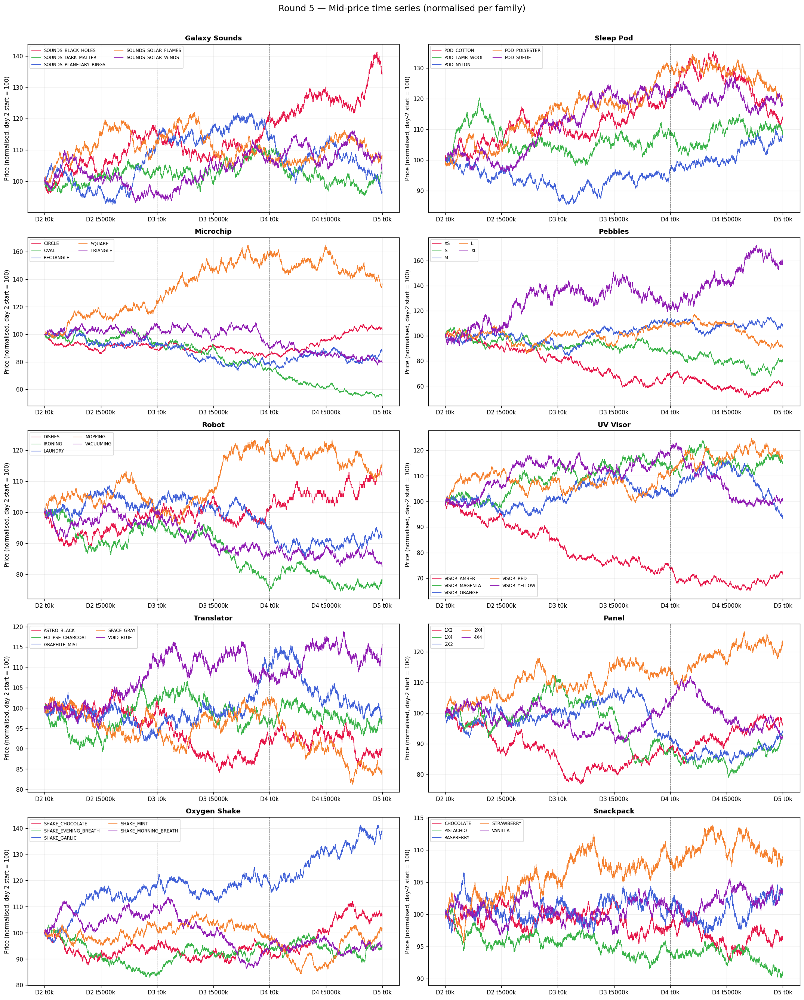

In [75]:
fig, axes = plt.subplots(5, 2, figsize=(18, 22))
axes = axes.flatten()

day_starts = [(d - DAYS[0]) * 1_000_000 for d in DAYS]
COLORS5 = ['#e6194b','#3cb44b','#4363d8','#f58231','#911eb4']

for ax, (fname, prods) in zip(axes, FAMILIES.items()):
    for p, col in zip(prods, COLORS5):
        if p not in mid.columns:
            continue
        series = mid[p].dropna()
        base   = series.iloc[0]
        ax.plot(series.index, series / base * 100, color=col, linewidth=0.8,
                label=p.split('_', 1)[-1])
    for ds in day_starts[1:]:
        ax.axvline(ds, color='black', linestyle='--', linewidth=0.7, alpha=0.5)
    ax.set_title(fname, fontsize=11, fontweight='bold')
    ax.set_ylabel('Price (normalised, day-2 start = 100)')
    ax.legend(fontsize=7, ncol=2)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(
        lambda x, _: f'D{DAYS[0] + int(x // 1_000_000)} t{int(x % 1_000_000 // 100)}k'))
    ax.grid(True, alpha=0.2)

fig.suptitle('Round 5 — Mid-price time series (normalised per family)', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 2 — Correlation matrix (all 50 products)

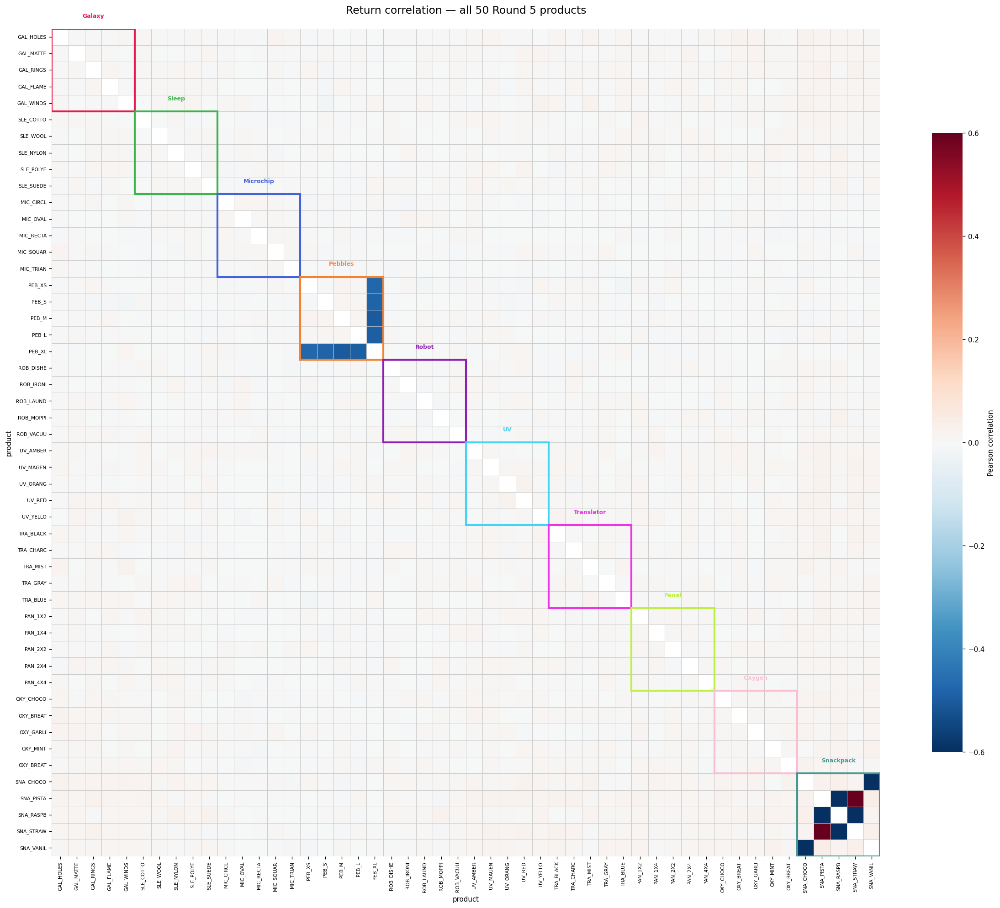

In [76]:
# Use log-returns for correlation (removes level effects)
log_ret = np.log(mid).diff().dropna()

# Reorder columns by family
ordered_cols = [p for prods in FAMILIES.values() for p in prods if p in log_ret.columns]
log_ret_ord  = log_ret[ordered_cols]
corr         = log_ret_ord.corr()

# Family colour bar
row_colors = []
for p in ordered_cols:
    for fname, prods in FAMILIES.items():
        if p in prods:
            row_colors.append(FAM_COLOR[fname])
            break

fig, ax = plt.subplots(figsize=(20, 17))
mask = np.zeros_like(corr, dtype=bool)
np.fill_diagonal(mask, True)

sns.heatmap(
    corr, ax=ax, mask=mask,
    cmap='RdBu_r', center=0, vmin=-0.6, vmax=0.6,
    xticklabels=[SHORT.get(p, p) for p in ordered_cols],
    yticklabels=[SHORT.get(p, p) for p in ordered_cols],
    linewidths=0.3, linecolor='#cccccc',
    annot=False, square=True, cbar_kws={'shrink': 0.7, 'label': 'Pearson correlation'}
)

# Draw family group boxes
pos = 0
for fname, prods in FAMILIES.items():
    n = sum(1 for p in prods if p in ordered_cols)
    rect = plt.Rectangle((pos, pos), n, n, fill=False,
                          edgecolor=FAM_COLOR[fname], linewidth=2.5)
    ax.add_patch(rect)
    ax.text(pos + n/2, pos - 0.6, fname.split()[0], ha='center', va='bottom',
            fontsize=7.5, color=FAM_COLOR[fname], fontweight='bold')
    pos += n

ax.set_title('Return correlation — all 50 Round 5 products', fontsize=14, pad=20)
plt.xticks(fontsize=6.5, rotation=90)
plt.yticks(fontsize=6.5, rotation=0)
plt.tight_layout()
plt.show()

## 3 — Intra-family correlation heatmaps

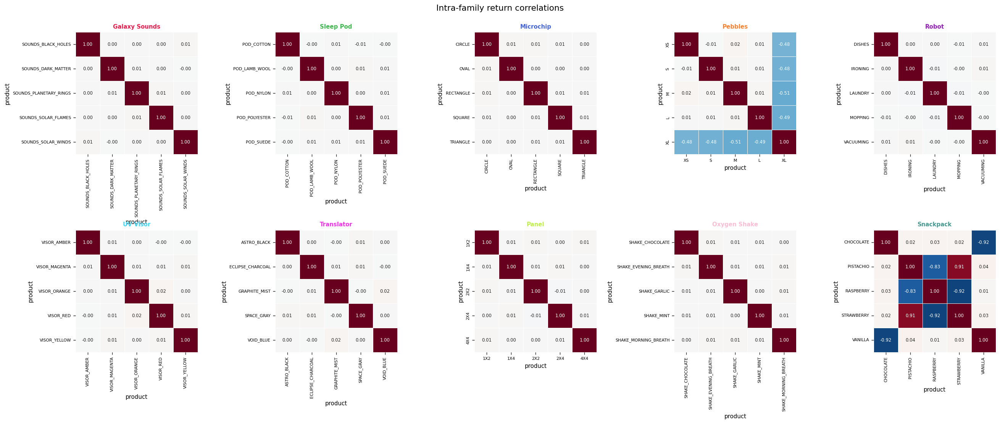

In [77]:
fig, axes = plt.subplots(2, 5, figsize=(22, 9))
axes = axes.flatten()

for ax, (fname, prods) in zip(axes, FAMILIES.items()):
    avail = [p for p in prods if p in log_ret.columns]
    sub   = log_ret[avail].corr()
    labels = [p.split('_', 1)[-1] for p in avail]
    sns.heatmap(sub, ax=ax, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
                annot=True, fmt='.2f', square=True,
                xticklabels=labels, yticklabels=labels,
                cbar=False, linewidths=0.5,
                annot_kws={'size': 7})
    ax.set_title(fname, fontsize=9, fontweight='bold',
                 color=FAM_COLOR[fname])
    ax.tick_params(labelsize=6.5)

fig.suptitle('Intra-family return correlations', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 4 — PEBBLES: basket arb
**XS + S + M + L + XL = 50 000 always (std ≈ 2.8).** This is a hard constraint — the strongest signal in the round.

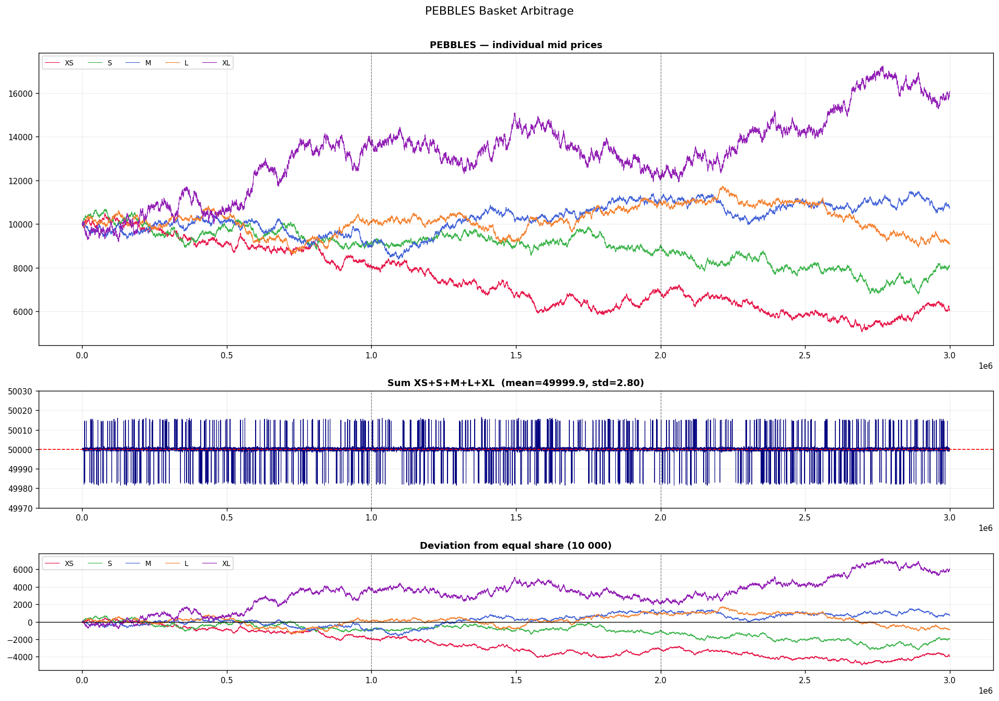

Sum stats: mean=49999.940, std=2.798, min=49982, max=50016
Constraint holds to within 2.8 per tick — near-perfect basket arb.


In [78]:
pebbles = FAMILIES['Pebbles']
peb_mid = mid[pebbles].dropna()
peb_sum = peb_mid.sum(axis=1)

fig, axes = plt.subplots(3, 1, figsize=(16, 11), gridspec_kw={'height_ratios': [2.5, 1, 1]})

# Raw price series
for p, col in zip(pebbles, COLORS5):
    axes[0].plot(peb_mid.index, peb_mid[p], linewidth=0.7, color=col,
                 label=p.split('_')[-1])
for ds in day_starts[1:]:
    axes[0].axvline(ds, color='black', linestyle='--', linewidth=0.7, alpha=0.5)
axes[0].set_title('PEBBLES — individual mid prices', fontweight='bold')
axes[0].legend(ncol=5, fontsize=8)
axes[0].grid(True, alpha=0.2)

# Basket sum
axes[1].plot(peb_sum.index, peb_sum, color='navy', linewidth=0.6)
axes[1].axhline(50000, color='red', linestyle='--', linewidth=1)
axes[1].set_title(f'Sum XS+S+M+L+XL  (mean={peb_sum.mean():.1f}, std={peb_sum.std():.2f})',
                  fontweight='bold')
axes[1].set_ylim(49970, 50030)
for ds in day_starts[1:]:
    axes[1].axvline(ds, color='black', linestyle='--', linewidth=0.7, alpha=0.5)
axes[1].grid(True, alpha=0.2)

# Deviation from equal share (50000/5 = 10000)
EQUAL_SHARE = 50000 / 5
for p, col in zip(pebbles, COLORS5):
    axes[2].plot(peb_mid.index, peb_mid[p] - EQUAL_SHARE,
                 linewidth=0.7, color=col, label=p.split('_')[-1])
axes[2].axhline(0, color='black', linewidth=0.8)
axes[2].set_title('Deviation from equal share (10 000)', fontweight='bold')
axes[2].legend(ncol=5, fontsize=8)
axes[2].grid(True, alpha=0.2)
for ds in day_starts[1:]:
    axes[2].axvline(ds, color='black', linestyle='--', linewidth=0.7, alpha=0.5)

plt.suptitle('PEBBLES Basket Arbitrage', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

print(f'Sum stats: mean={peb_sum.mean():.3f}, std={peb_sum.std():.3f}, '
      f'min={peb_sum.min():.0f}, max={peb_sum.max():.0f}')
print(f'Constraint holds to within {peb_sum.std():.1f} per tick — near-perfect basket arb.')

## 5 — SNACKPACK: stable fair values

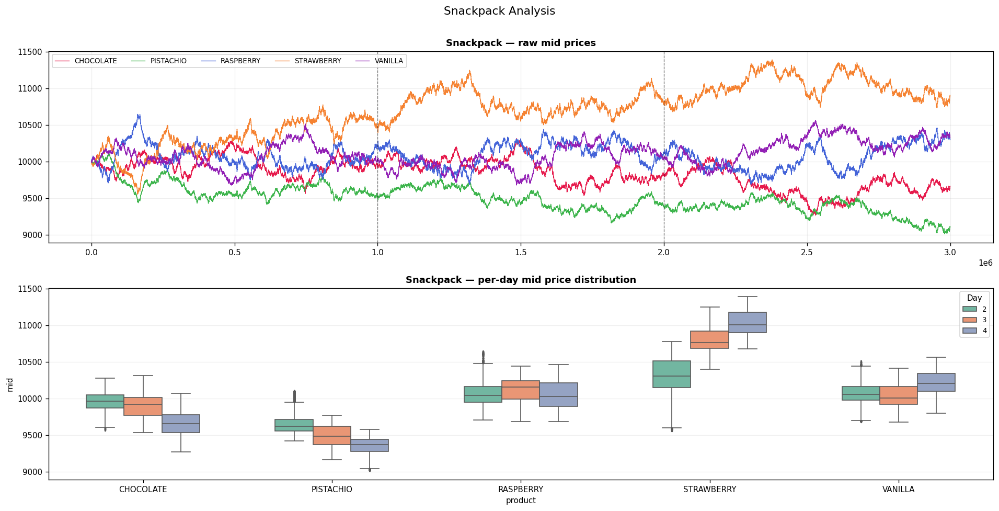


Per-day means:
  CHOCOLATE             d2=9961  d3=9900  d4=9669   range=293   spread=16.5
  PISTACHIO             d2=9656  d3=9487  d4=9345   range=311   spread=15.9
  RASPBERRY             d2=10065  d3=10117  d4=10051   range=66   spread=16.8
  STRAWBERRY            d2=10295  d3=10795  d4=11030   range=735   spread=17.8
  VANILLA               d2=10064  d3=10027  d4=10202   range=175   spread=16.9


In [79]:
snacks = FAMILIES['Snackpack']

fig, axes = plt.subplots(2, 1, figsize=(16, 8))

# Time series
for p, col in zip(snacks, COLORS5):
    s = mid[p].dropna()
    axes[0].plot(s.index, s, linewidth=0.8, color=col, label=p.split('_', 1)[-1])
for ds in day_starts[1:]:
    axes[0].axvline(ds, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
axes[0].set_title('Snackpack — raw mid prices', fontweight='bold')
axes[0].legend(ncol=5, fontsize=8)
axes[0].grid(True, alpha=0.2)

# Per-day box plot
snack_by_day = []
for d in DAYS:
    sub = prices[prices['day'] == d]
    for p in snacks:
        vals = sub[sub['product'] == p]['mid_price'].dropna().tolist()
        for v in vals:
            snack_by_day.append({'day': d, 'product': p.split('_',1)[-1], 'mid': v})
sdf = pd.DataFrame(snack_by_day)

import warnings
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    sns.boxplot(data=sdf, x='product', y='mid', hue='day', ax=axes[1], palette='Set2',
                width=0.6, fliersize=1)
axes[1].set_title('Snackpack — per-day mid price distribution', fontweight='bold')
axes[1].grid(True, alpha=0.2, axis='y')
axes[1].legend(title='Day', fontsize=8)

plt.suptitle('Snackpack Analysis', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

# Day-mean stability table
print('\nPer-day means:')
for p in snacks:
    means = [prices[(prices['day']==d) & (prices['product']==p)]['mid_price'].mean() for d in DAYS]
    rng   = max(means) - min(means)
    sp    = prices[prices['product']==p].eval('ask_price_1 - bid_price_1').mean()
    print(f"  {p.split('_',1)[-1]:<20}  " +
          '  '.join(f'd{d}={m:.0f}' for d,m in zip(DAYS,means)) +
          f'   range={rng:.0f}   spread={sp:.1f}')

## 6 — Robot: mean reversion analysis

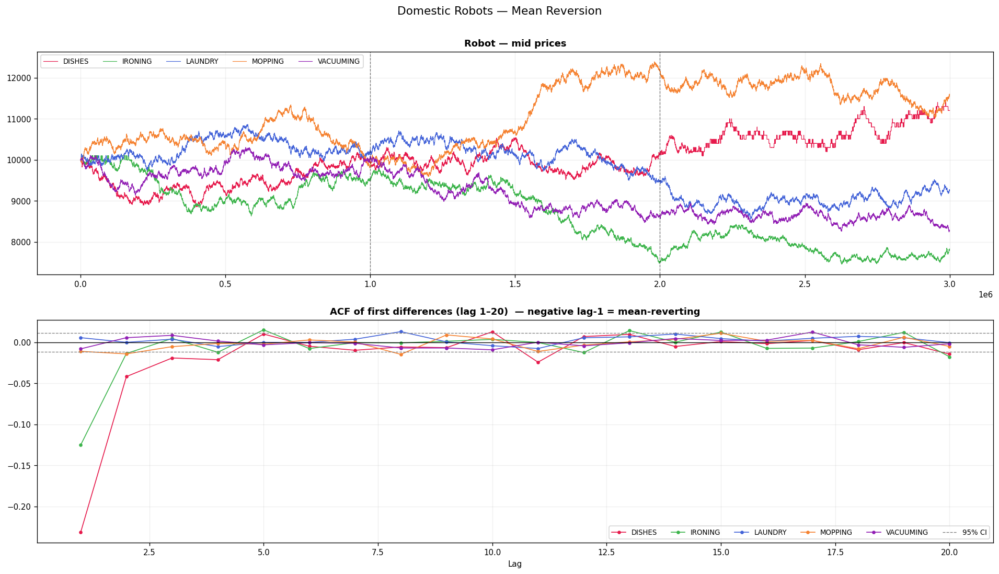


Lag-1 ACF of returns:
  DISHES        ac1=-0.2317   spread=7.4
  IRONING       ac1=-0.1253   spread=6.4
  LAUNDRY       ac1=+0.0057   spread=7.2
  MOPPING       ac1=-0.0110   spread=8.0
  VACUUMING     ac1=-0.0080   spread=6.8


In [80]:
robots = FAMILIES['Robot']

fig, axes = plt.subplots(2, 1, figsize=(16, 9))

for p, col in zip(robots, COLORS5):
    s = mid[p].dropna()
    axes[0].plot(s.index, s, linewidth=0.7, color=col, label=p.split('_',1)[-1])
for ds in day_starts[1:]:
    axes[0].axvline(ds, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
axes[0].set_title('Robot — mid prices', fontweight='bold')
axes[0].legend(ncol=5, fontsize=8)
axes[0].grid(True, alpha=0.2)

# ACF plot (lag 1-20)
from statsmodels.tsa.stattools import acf
MAX_LAG = 20
for p, col in zip(robots, COLORS5):
    s = mid[p].dropna()
    a = acf(s.diff().dropna(), nlags=MAX_LAG, fft=True)
    axes[1].plot(range(1, MAX_LAG+1), a[1:], marker='o', markersize=3,
                 linewidth=1, color=col, label=p.split('_',1)[-1])
axes[1].axhline(0, color='black', linewidth=0.8)
conf = 1.96 / np.sqrt(len(mid))
axes[1].axhline(conf,  color='grey', linestyle='--', linewidth=0.8, label='95% CI')
axes[1].axhline(-conf, color='grey', linestyle='--', linewidth=0.8)
axes[1].set_title('ACF of first differences (lag 1–20)  — negative lag-1 = mean-reverting',
                  fontweight='bold')
axes[1].set_xlabel('Lag')
axes[1].legend(ncol=6, fontsize=8)
axes[1].grid(True, alpha=0.2)

plt.suptitle('Domestic Robots — Mean Reversion', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

print('\nLag-1 ACF of returns:')
for p in robots:
    s = mid[p].dropna()
    a = acf(s.diff().dropna(), nlags=1, fft=True)
    sp = prices[prices['product']==p].eval('ask_price_1 - bid_price_1').mean()
    print(f"  {p.split('_',1)[-1]:<12}  ac1={a[1]:+.4f}   spread={sp:.1f}")

## 7 — Oxygen Shake: mean reversion

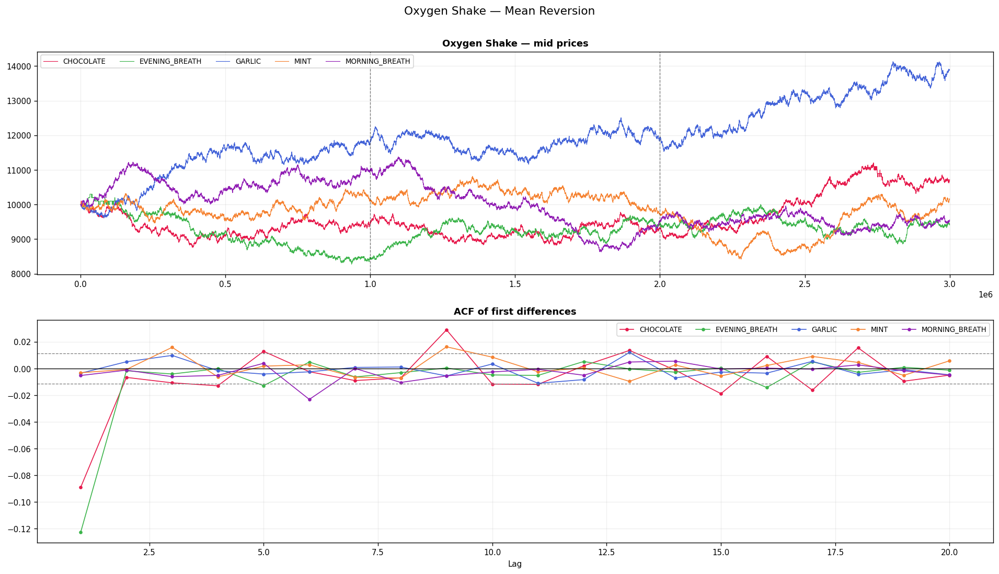

In [81]:
shakes = FAMILIES['Oxygen Shake']

fig, axes = plt.subplots(2, 1, figsize=(16, 9))

for p, col in zip(shakes, COLORS5):
    s = mid[p].dropna()
    axes[0].plot(s.index, s, linewidth=0.7, color=col, label=p.split('_',2)[-1])
for ds in day_starts[1:]:
    axes[0].axvline(ds, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
axes[0].set_title('Oxygen Shake — mid prices', fontweight='bold')
axes[0].legend(ncol=5, fontsize=8)
axes[0].grid(True, alpha=0.2)

MAX_LAG = 20
for p, col in zip(shakes, COLORS5):
    s = mid[p].dropna()
    a = acf(s.diff().dropna(), nlags=MAX_LAG, fft=True)
    axes[1].plot(range(1, MAX_LAG+1), a[1:], marker='o', markersize=3,
                 linewidth=1, color=col, label=p.split('_',2)[-1])
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].axhline(conf,  color='grey', linestyle='--', linewidth=0.8)
axes[1].axhline(-conf, color='grey', linestyle='--', linewidth=0.8)
axes[1].set_title('ACF of first differences', fontweight='bold')
axes[1].set_xlabel('Lag')
axes[1].legend(ncol=5, fontsize=8)
axes[1].grid(True, alpha=0.2)

plt.suptitle('Oxygen Shake — Mean Reversion', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 8 — Trending products

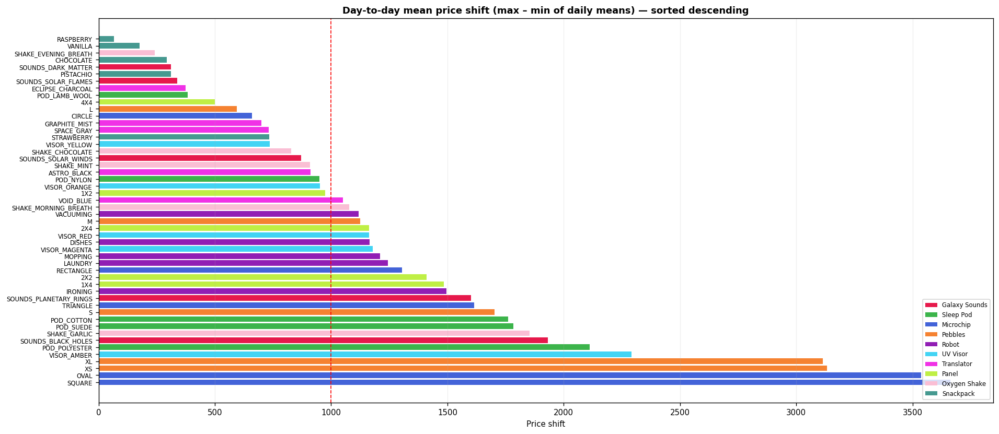


Products with day-shift > 1000 (static FV dangerous):
  MICROCHIP_SQUARE                              3663
  MICROCHIP_OVAL                                3538
  PEBBLES_XS                                    3133
  PEBBLES_XL                                    3115
  UV_VISOR_AMBER                                2292
  SLEEP_POD_POLYESTER                           2113
  GALAXY_SOUNDS_BLACK_HOLES                     1932
  OXYGEN_SHAKE_GARLIC                           1853
  SLEEP_POD_SUEDE                               1783
  SLEEP_POD_COTTON                              1760
  PEBBLES_S                                     1701
  MICROCHIP_TRIANGLE                            1615
  GALAXY_SOUNDS_PLANETARY_RINGS                 1602
  ROBOT_IRONING                                 1496
  PANEL_1X4                                     1485
  PANEL_2X2                                     1411
  MICROCHIP_RECTANGLE                           1304
  ROBOT_LAUNDRY                             

In [82]:
# Compute day-to-day mean shift for all products
shifts = {}
for p in prices['product'].unique():
    d_means = [prices[(prices['day']==d) & (prices['product']==p)]['mid_price'].mean()
               for d in DAYS]
    shifts[p] = max(d_means) - min(d_means)
shift_series = pd.Series(shifts).sort_values(ascending=False)

# Colour by family
prod_to_fam = {p: f for f, prods in FAMILIES.items() for p in prods}
bar_colors  = [FAM_COLOR.get(prod_to_fam.get(p, ''), '#888888') for p in shift_series.index]

fig, ax = plt.subplots(figsize=(16, 7))
ax.barh(range(len(shift_series)), shift_series.values, color=bar_colors)
ax.set_yticks(range(len(shift_series)))
ax.set_yticklabels([p.split('_',1)[-1] for p in shift_series.index], fontsize=7)
ax.axvline(1000, color='red', linestyle='--', linewidth=1, label='1000 threshold')
ax.set_title('Day-to-day mean price shift (max – min of daily means) — sorted descending',
             fontweight='bold')
ax.set_xlabel('Price shift')
ax.grid(True, alpha=0.2, axis='x')

# Legend patches
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=FAM_COLOR[f], label=f) for f in FAMILIES]
ax.legend(handles=legend_elements, fontsize=7, loc='lower right')
ax.legend(handles=legend_elements, fontsize=7, loc='lower right')

plt.tight_layout()
plt.show()

print(f'\nProducts with day-shift > 1000 (static FV dangerous):')
for p, v in shift_series[shift_series > 1000].items():
    print(f'  {p:<45} {v:.0f}')

## 9 — Spread vs volatility (MM profitability map)

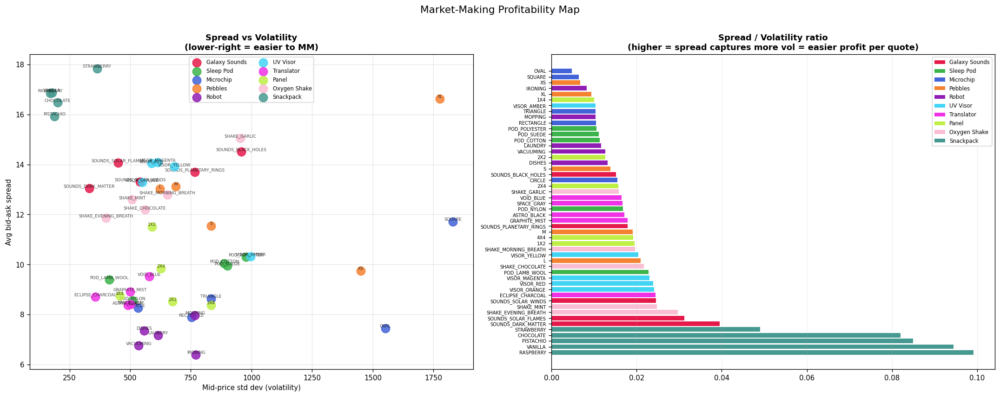


Top-10 MM targets (spread/vol):
                    product    spread        vol  sp_over_vol       ac1
        SNACKPACK_RASPBERRY 16.842467 169.813848     0.099182 -0.016977
          SNACKPACK_VANILLA 16.868667 178.514627     0.094495 -0.026993
        SNACKPACK_PISTACHIO 15.925633 187.495035     0.084939 -0.025015
        SNACKPACK_CHOCOLATE 16.471167 200.733326     0.082055 -0.030963
       SNACKPACK_STRAWBERRY 17.826467 363.573111     0.049031 -0.013691
  GALAXY_SOUNDS_DARK_MATTER 13.050833 330.700516     0.039464 -0.011554
 GALAXY_SOUNDS_SOLAR_FLAMES 14.071533 450.150431     0.031260 -0.011994
OXYGEN_SHAKE_EVENING_BREATH 11.860467 399.821495     0.029664 -0.117962
          OXYGEN_SHAKE_MINT 12.593567 508.131123     0.024784 -0.003201
  GALAXY_SOUNDS_SOLAR_WINDS 13.301267 541.110756     0.024581 -0.007278


In [83]:
records = []
for p in prices['product'].unique():
    sub = prices[prices['product'] == p]
    sp  = (sub['ask_price_1'] - sub['bid_price_1']).mean()
    mids = sub['mid_price'].dropna()
    vol  = mids.std()
    ac1_val = 0.0
    if p in log_ret.columns:
        diff = log_ret[p].dropna()
        if len(diff) > 2:
            ac1_val = diff.autocorr(lag=1)
    fam  = prod_to_fam.get(p, 'Unknown')
    records.append({'product': p, 'family': fam,
                    'spread': sp, 'vol': vol,
                    'sp_over_vol': sp / vol if vol > 0 else 0,
                    'ac1': ac1_val})

rdf = pd.DataFrame(records).sort_values('sp_over_vol', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Scatter: vol vs spread, sized by |ac1|
for fname, prods in FAMILIES.items():
    sub = rdf[rdf['family'] == fname]
    axes[0].scatter(sub['vol'], sub['spread'], s=120, color=FAM_COLOR[fname],
                    label=fname, zorder=3, alpha=0.85)
    for _, row in sub.iterrows():
        axes[0].annotate(row['product'].split('_',1)[-1],
                         (row['vol'], row['spread']),
                         fontsize=5.5, ha='center', va='bottom', alpha=0.7)
axes[0].set_xlabel('Mid-price std dev (volatility)')
axes[0].set_ylabel('Avg bid-ask spread')
axes[0].set_title('Spread vs Volatility\n(lower-right = easier to MM)', fontweight='bold')
axes[0].legend(fontsize=7, ncol=2)
axes[0].grid(True, alpha=0.3)

# Bar: spread/vol ratio — lower is better for MM
bar_c = [FAM_COLOR.get(prod_to_fam.get(p,''),'#888') for p in rdf['product']]
axes[1].barh(range(len(rdf)), rdf['sp_over_vol'], color=bar_c)
axes[1].set_yticks(range(len(rdf)))
axes[1].set_yticklabels([p.split('_',1)[-1] for p in rdf['product']], fontsize=6)
axes[1].set_title('Spread / Volatility ratio\n(higher = spread captures more vol = easier profit per quote)',
                  fontweight='bold')
axes[1].grid(True, alpha=0.2, axis='x')
legend_elements = [Patch(facecolor=FAM_COLOR[f], label=f) for f in FAMILIES]
axes[1].legend(handles=legend_elements, fontsize=7)

plt.suptitle('Market-Making Profitability Map', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

print('\nTop-10 MM targets (spread/vol):')
print(rdf[['product','spread','vol','sp_over_vol','ac1']].head(10).to_string(index=False))

## 10 — Summary stats table (all 50 products)

In [84]:
summary_rows = []
for p in prices['product'].unique():
    sub   = prices[prices['product'] == p]
    mids  = sub['mid_price'].dropna()
    sp    = (sub['ask_price_1'] - sub['bid_price_1']).mean()
    d_means = [prices[(prices['day']==d) & (prices['product']==p)]['mid_price'].mean()
               for d in DAYS]
    dr    = max(d_means) - min(d_means)
    ac1_v = log_ret[p].dropna().autocorr(lag=1) if p in log_ret.columns else np.nan
    fam   = prod_to_fam.get(p, '')
    summary_rows.append({
        'Family': fam,
        'Product': p.split('_', 1)[-1],
        'Mean': round(mids.mean(), 0),
        'Std':  round(mids.std(),  0),
        'Spread': round(sp, 1),
        'Sp/Vol': round(sp / mids.std(), 4),
        'DayRange': round(dr, 0),
        'AC1':  round(ac1_v, 4) if pd.notna(ac1_v) else np.nan,
        'Signal': ('BASKET ARB' if fam == 'Pebbles'
                   else 'STRONG MR' if (pd.notna(ac1_v) and ac1_v < -0.10)
                   else 'mild MR'   if (pd.notna(ac1_v) and ac1_v < -0.03)
                   else 'TRENDING'  if dr > 1500
                   else 'neutral'),
    })

sdf = (pd.DataFrame(summary_rows)
         .sort_values(['Family','Product'])
         .reset_index(drop=True))

def colour_signal(val):
    c = {'BASKET ARB':'background-color:#d4edda',
         'STRONG MR': 'background-color:#cce5ff',
         'mild MR':   'background-color:#e8f4fd',
         'TRENDING':  'background-color:#fff3cd',
         'neutral':   ''}.get(val, '')
    return c

styled = (sdf.style
    .applymap(colour_signal, subset=['Signal'])
    .format({'Mean':'{:.0f}', 'Std':'{:.0f}', 'Spread':'{:.1f}',
             'Sp/Vol':'{:.4f}', 'DayRange':'{:.0f}', 'AC1':'{:+.4f}'})
    .set_caption('Round 5 — Product Summary (all 50)')
)
styled

/var/folders/m1/r509ltd163s9j5gyx98z2mkr0000gn/T/ipykernel_17141/2857432235.py:40: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  .applymap(colour_signal, subset=['Signal'])


,Family,Product,Mean,Std,Spread,Sp/Vol,DayRange,AC1,Signal
0,Galaxy Sounds,SOUNDS_BLACK_HOLES,11467,958,14.5,0.0151,1932,-0.0167,TRENDING
1,Galaxy Sounds,SOUNDS_DARK_MATTER,10227,331,13.1,0.0395,310,-0.0116,neutral
2,Galaxy Sounds,SOUNDS_PLANETARY_RINGS,10767,766,13.7,0.0179,1602,-0.0031,TRENDING
3,Galaxy Sounds,SOUNDS_SOLAR_FLAMES,11093,450,14.1,0.0313,338,-0.0120,neutral
4,Galaxy Sounds,SOUNDS_SOLAR_WINDS,10438,541,13.3,0.0246,870,-0.0073,neutral
5,Microchip,CIRCLE,9215,533,8.3,0.0155,659,-0.0050,neutral
6,Microchip,OVAL,8180,1552,7.4,0.0048,3538,-0.0074,TRENDING
7,Microchip,RECTANGLE,8732,752,7.9,0.0105,1304,-0.0025,neutral
8,Microchip,SQUARE,13595,1830,11.7,0.0064,3663,-0.0220,TRENDING
9,Microchip,TRIANGLE,9686,833,8.6,0.0104,1615,-0.0077,TRENDING


## 11 — Family deep-dives: Microchip, UV Visor (trending)

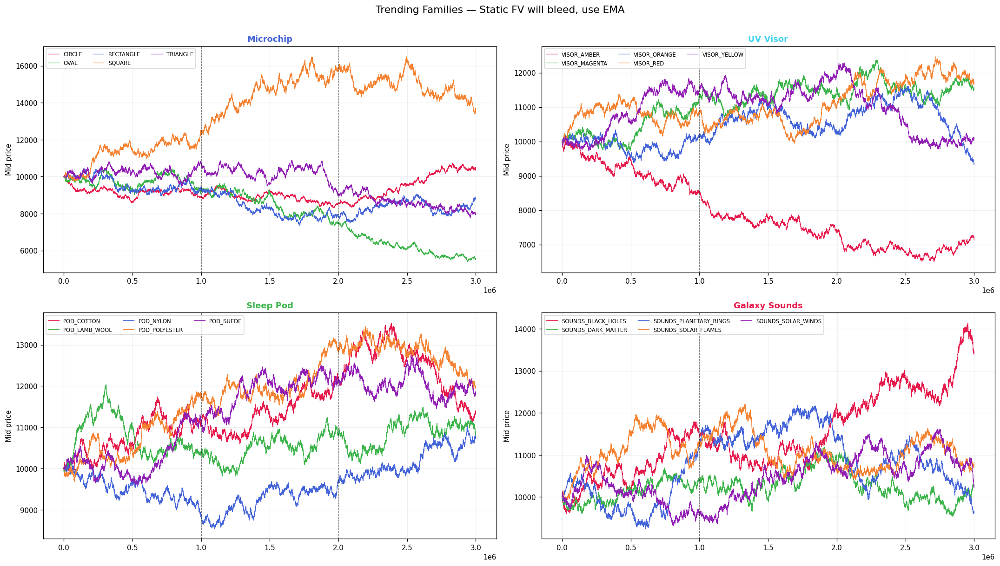

In [85]:
trending_fams = ['Microchip', 'UV Visor', 'Sleep Pod', 'Galaxy Sounds']

fig, axes = plt.subplots(2, 2, figsize=(18, 10))
axes = axes.flatten()

for ax, fname in zip(axes, trending_fams):
    prods = FAMILIES[fname]
    for p, col in zip(prods, COLORS5):
        if p not in mid.columns: continue
        s = mid[p].dropna()
        ax.plot(s.index, s, linewidth=0.8, color=col, label=p.split('_',1)[-1])
    for ds in day_starts[1:]:
        ax.axvline(ds, color='black', linestyle='--', linewidth=0.7, alpha=0.5)
    ax.set_title(fname, fontweight='bold', color=FAM_COLOR[fname])
    ax.legend(ncol=3, fontsize=7)
    ax.grid(True, alpha=0.2)
    ax.set_ylabel('Mid price')

plt.suptitle('Trending Families — Static FV will bleed, use EMA', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 12 — Panel, Translator, UV Visor (remaining families)

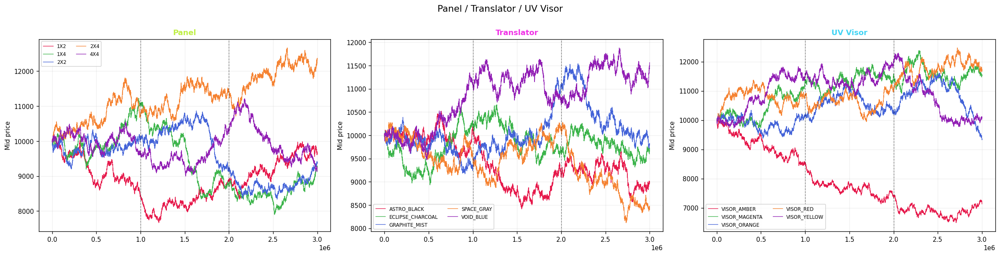

In [86]:
remaining = ['Panel', 'Translator', 'UV Visor']

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, fname in zip(axes, remaining):
    prods = FAMILIES[fname]
    for p, col in zip(prods, COLORS5):
        s = mid[p].dropna()
        ax.plot(s.index, s, linewidth=0.8, color=col, label=p.split('_',1)[-1])
    for ds in day_starts[1:]:
        ax.axvline(ds, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
    ax.set_title(fname, fontweight='bold', color=FAM_COLOR[fname])
    ax.legend(ncol=2, fontsize=7)
    ax.grid(True, alpha=0.2)
    ax.set_ylabel('Mid price')

plt.suptitle('Panel / Translator / UV Visor', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 13 — Strategy Summary

| Priority | Strategy | Products | Rationale |
|---|---|---|---|
| ★★★★★ | **Basket Arb** | PEBBLES (all 5) | XS+S+M+L+XL = 50 000 always (std=2.8). Hard constraint. Buy underpriced, sell overpriced every tick. |
| ★★★★☆ | **Strong MR** | ROBOT_DISHES, ROBOT_IRONING | ac1 = −0.23, −0.13. Very tight spread (~7). Use MR signal aggressively. Rolling EMA for drifting FV. |
| ★★★★☆ | **Strong MR** | OXYGEN_SHAKE_EVENING_BREATH, CHOCOLATE | ac1 = −0.12, −0.09. Spread ~12. |
| ★★★☆☆ | **MM (stable FV)** | SNACKPACK_RASPBERRY, VANILLA, PISTACHIO | Day-mean range < 175. FVs near-static. Post inside wide spread (~17) to collect premium. |
| ★★★☆☆ | **MM + EMA FV** | ROBOT_MOPPING/VACUUMING/LAUNDRY | Moderate MR. Day-mean drifts → use short EMA for FV anchor. |
| ★★☆☆☆ | **EMA MM** | TRANSLATOR, SLEEP_POD, PANEL | Mild drift, moderate spreads. EMA-blended FV, conservative sizing. |
| ★★☆☆☆ | **Momentum / EMA** | MICROCHIP_SQUARE/OVAL, UV_VISOR_AMBER, PEBBLES_XL/XS | Day shifts > 2000. Static FV bleeds. EMA or momentum signal required. |
| ★★☆☆☆ | **EMA MM** | GALAXY_SOUNDS, OXYGEN_SHAKE_GARLIC | Moderate vol, moderate drift. |

**Position limit = 10 on every product.**  
PEBBLES basket arb requires holding positions in all 5 simultaneously → max exposure = 50 units across the family.  
SNACKPACK: wide spread but slow moves → MM at pos-limit is safe.  
ROBOT_DISHES: fast MR → aggressive MR entry/exit optimal.

**Open questions:**
- Does SNACKPACK sum (cv=0.38%) also offer a weaker basket signal?
- Is there a PEBBLES "fair share" formula (not equal-weight 10 000) that tightens the residual further?
- Do PANEL sizes have a tile-area cost model? (per-area price falls as size grows: not linear)
- Bot activity: only `XIRECS` visible in trades — no directional signal available from bot IDs.

## 14 — Sleep Pods: price comparison with time shifts

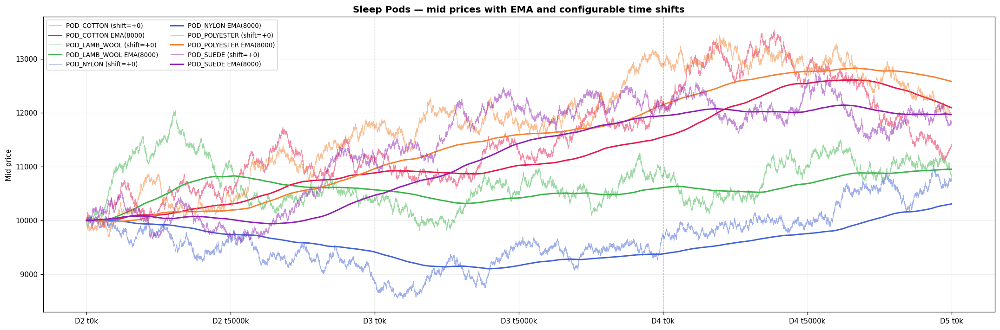

In [87]:
# ── CONFIGURE HERE ─────────────────────────────────────────────────────────────
SLEEP_PODS = [
    "SLEEP_POD_COTTON",
    "SLEEP_POD_LAMB_WOOL",
    "SLEEP_POD_NYLON",
    "SLEEP_POD_POLYESTER",
    "SLEEP_POD_SUEDE",
]

# Positive = shift right (delay), negative = shift left (advance). Units = ticks.
SHIFTS = {
    "SLEEP_POD_COTTON":    0,
    "SLEEP_POD_LAMB_WOOL": 0,
    "SLEEP_POD_NYLON":     0,
    "SLEEP_POD_POLYESTER": 0,
    "SLEEP_POD_SUEDE":     0,
}

# EMA span per product (None = no EMA drawn for that product).
# Span is the pandas ewm span parameter: larger = slower/smoother EMA.
EMA_SPANS = {
    "SLEEP_POD_COTTON":    8000,
    "SLEEP_POD_LAMB_WOOL": 8000,
    "SLEEP_POD_NYLON":     8000,
    "SLEEP_POD_POLYESTER": 8000,
    "SLEEP_POD_SUEDE":     8000,
}
# ────────────────────────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(18, 6))

for p, col in zip(SLEEP_PODS, COLORS5):
    if p not in mid.columns:
        print(f"{p} not found")
        continue
    series = mid[p].dropna()
    shift  = SHIFTS.get(p, 0)
    idx    = series.index + shift
    label  = p.split('_', 1)[-1]

    ax.plot(idx, series.values, color=col, linewidth=0.8, alpha=0.5,
            label=f"{label} (shift={shift:+d})")

    span = EMA_SPANS.get(p)
    if span is not None:
        ema = series.ewm(span=span, adjust=False).mean()
        ax.plot(idx, ema.values, color=col, linewidth=1.8,
                label=f"{label} EMA({span})")

for ds in day_starts[1:]:
    ax.axvline(ds, color='black', linestyle='--', linewidth=0.7, alpha=0.5)

ax.set_title('Sleep Pods — mid prices with EMA and configurable time shifts',
             fontweight='bold', fontsize=12)
ax.set_ylabel('Mid price')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f'D{DAYS[0] + int(x // 1_000_000)} t{int(x % 1_000_000 // 100)}k'))
ax.legend(fontsize=8, ncol=2)
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()


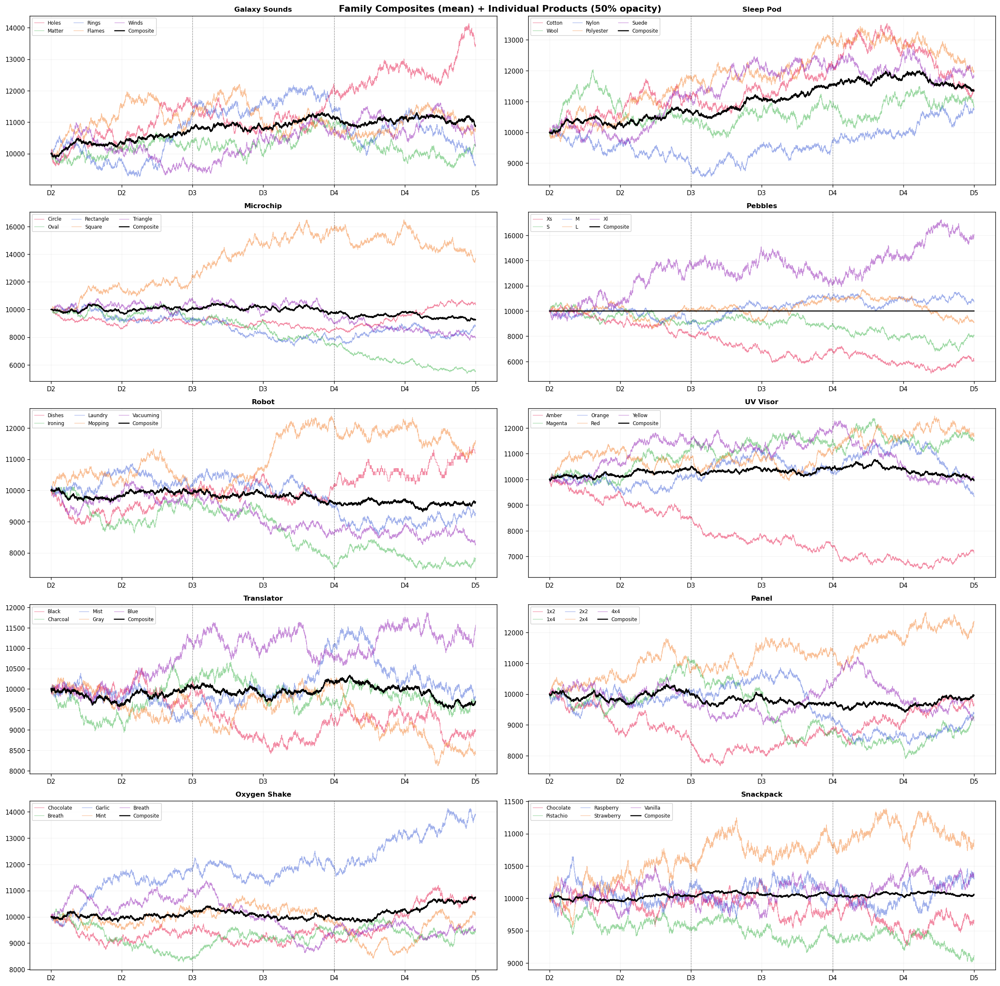

In [88]:
## 16 — Family composites: mean price + individual stocks at 50% opacity

COLORS5 = ['#e6194b', '#3cb44b', '#4363d8', '#f58231', '#911eb4']
n_fams = len(FAMILIES)
ncols = 2
nrows = (n_fams + 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(20, nrows * 4), sharex=False)
axes = axes.flatten()

for ax, (fname, prods) in zip(axes, FAMILIES.items()):
    fam_mid = mid[prods].dropna(how='all')
    idx = fam_mid.index

    # Individual products at 50% opacity
    for prod, col in zip(prods, COLORS5):
        s = fam_mid[prod].dropna()
        short = prod.split('_')[-1].capitalize()
        ax.plot(s.index, s.values, color=col, lw=0.7, alpha=0.5, label=short)

    # Composite (mean across products)
    composite = fam_mid.mean(axis=1)
    ax.plot(composite.index, composite.values, color='black', lw=1.5,
            label='Composite', zorder=5)

    # Day dividers
    for d in DAYS[1:]:
        ax.axvline((d - DAYS[0]) * 1_000_000, color='black', ls='--', lw=0.7, alpha=0.4)

    ax.set_title(fname, fontweight='bold', fontsize=10)
    ax.legend(fontsize=7, ncol=3, loc='upper left')
    ax.grid(True, alpha=0.15)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(
        lambda x, _: f'D{DAYS[0] + int(x // 1_000_000)}'
    ))

# Hide unused axes
for ax in axes[n_fams:]:
    ax.set_visible(False)

fig.suptitle('Family Composites (mean) + Individual Products (50% opacity)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


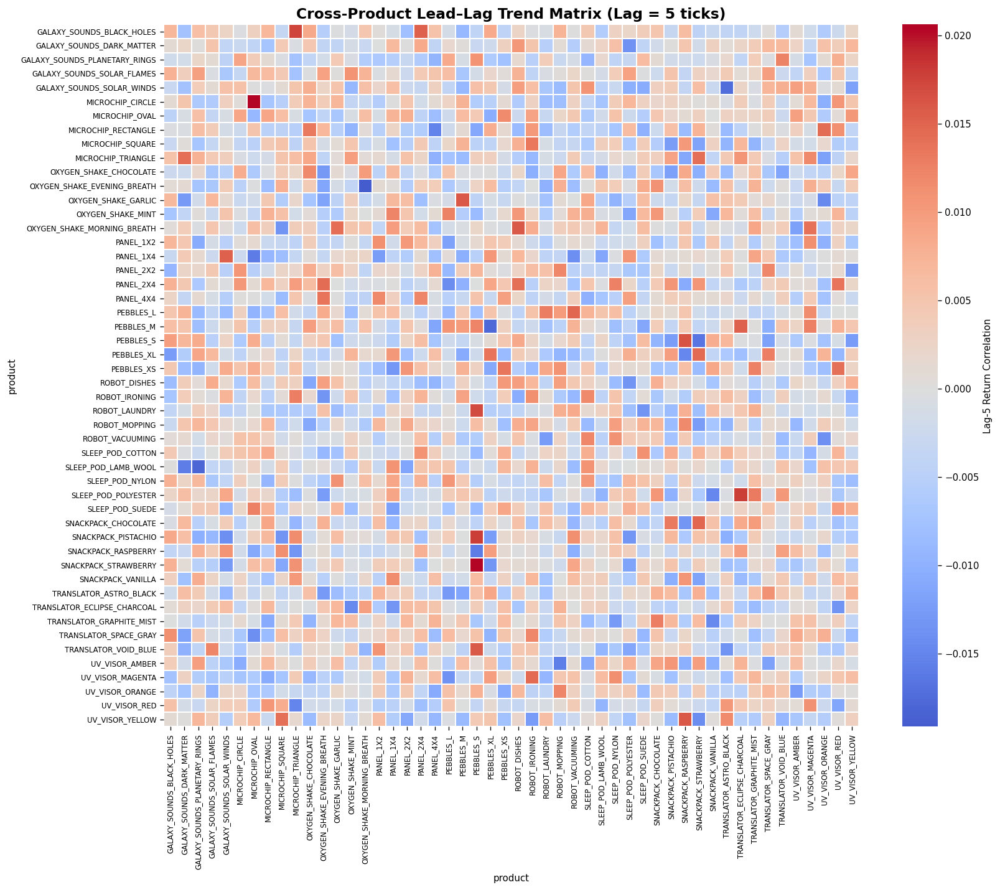

In [89]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ── 1. Flatten all products ────────────────────────────────────────────────
all_products = sorted({p for prods in FAMILIES.values() for p in prods})
mid_all = mid[all_products]

# ── 2. Log returns (core signal space) ─────────────────────────────────────
log_ret = np.log(mid_all).diff().fillna(0)

# ── 3. Choose lag (key parameter) ─────────────────────────────────────────
LAG = 5   # try 1, 5, 10, 20 for regime sensitivity

# ── 4. Build lead–lag matrix ──────────────────────────────────────────────
products = log_ret.columns
lead_lag_corr = pd.DataFrame(index=products, columns=products, dtype=float)

for p1 in products:   # predictor
    for p2 in products:  # target
    
        x = log_ret[p1].shift(LAG)
        y = log_ret[p2]

        valid = ~(x.isna() | y.isna())
        if valid.sum() > 20:
            lead_lag_corr.loc[p1, p2] = x[valid].corr(y[valid])
        else:
            lead_lag_corr.loc[p1, p2] = np.nan

# ── 5. Plot heatmap ───────────────────────────────────────────────────────
plt.figure(figsize=(14, 12))
sns.heatmap(
    lead_lag_corr,
    cmap='coolwarm',
    center=0,
    linewidths=0.2,
    cbar_kws={'label': f'Lag-{LAG} Return Correlation'}
)

plt.title(f'Cross-Product Lead–Lag Trend Matrix (Lag = {LAG} ticks)',
          fontsize=14, fontweight='bold')

plt.xticks(rotation=90, fontsize=7)
plt.yticks(fontsize=7)
plt.tight_layout()
plt.show()

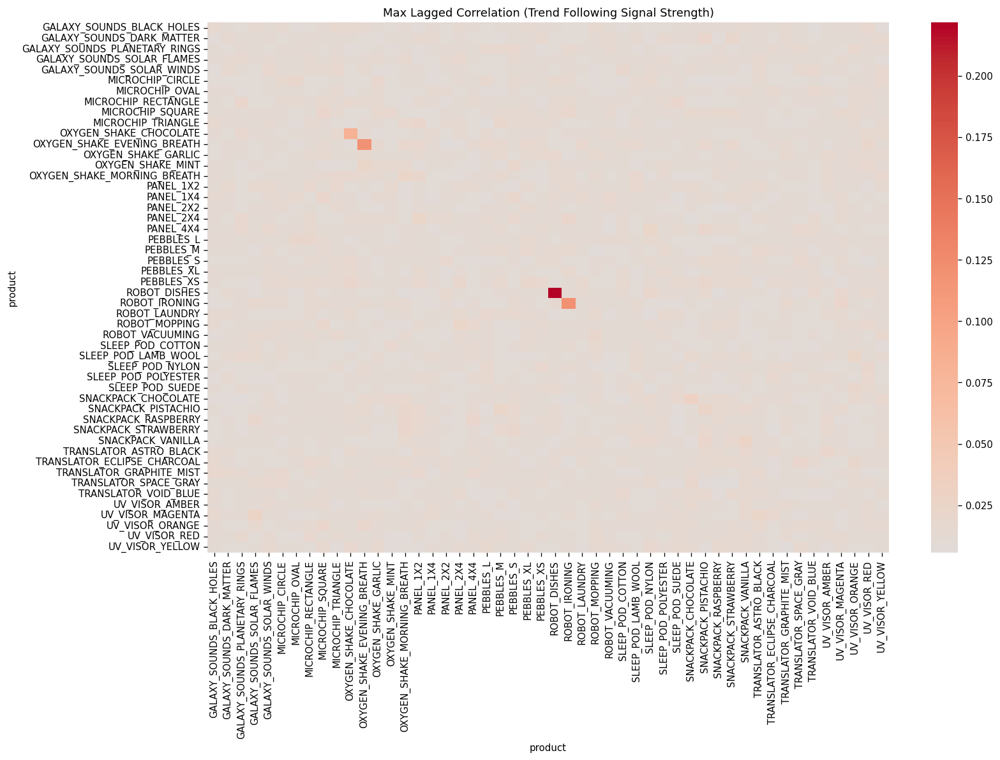

In [90]:
## Cross-product lag correlation heatmap (trend-following signal)

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# combine all products
all_products = mid.columns
logret = np.log(mid[all_products]).diff()

MAX_LAG = 20  # ticks

corr_matrix = pd.DataFrame(
    index=all_products,
    columns=all_products,
    dtype=float
)

for p1 in all_products:
    for p2 in all_products:
        best_corr = 0

        for lag in range(1, MAX_LAG + 1):
            r1 = logret[p1].shift(lag)
            r2 = logret[p2]

            c = r1.corr(r2)
            if pd.notna(c):
                best_corr = max(best_corr, abs(c))

        corr_matrix.loc[p1, p2] = best_corr

plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix.astype(float),
            cmap='coolwarm',
            center=0.0)

plt.title("Max Lagged Correlation (Trend Following Signal Strength)")
plt.tight_layout()
plt.show()

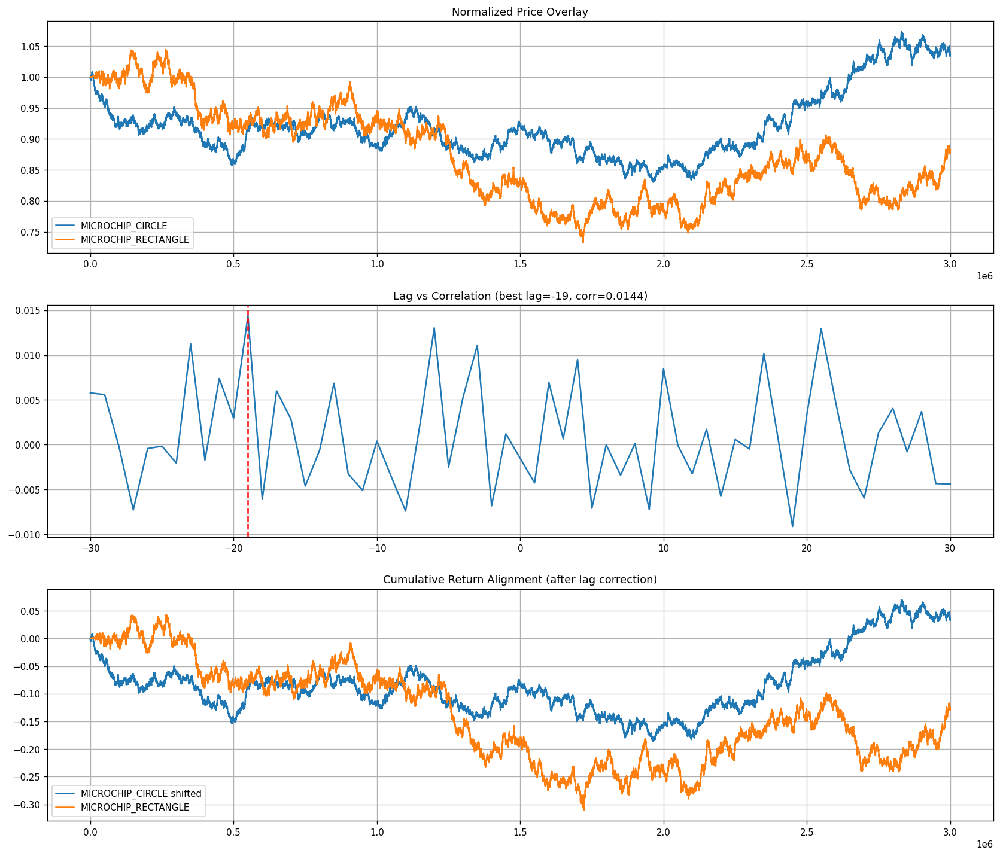

{'lag': -19, 'corr': 0.014398872089225313}


In [91]:
import numpy as np
import matplotlib.pyplot as plt

def lag_visual_analysis(mid, p1, p2, max_lag=30):

    # ─────────────────────────────────────────────
    # 1. LOG RETURNS (better than raw price)
    # ─────────────────────────────────────────────
    r1 = np.log(mid[p1]).diff()
    r2 = np.log(mid[p2]).diff()

    # ─────────────────────────────────────────────
    # 2. FIND BEST LAG
    # ─────────────────────────────────────────────
    lags = []
    corrs = []

    best = {"lag": 0, "corr": 0}

    for lag in range(-max_lag, max_lag + 1):
        if lag == 0:
            continue

        if lag > 0:
            x = r1.shift(lag)
            y = r2
        else:
            x = r1
            y = r2.shift(-lag)

        c = x.corr(y)

        lags.append(lag)
        corrs.append(c)

        if np.isfinite(c) and abs(c) > abs(best["corr"]):
            best = {"lag": lag, "corr": c}

    # ─────────────────────────────────────────────
    # 3. PLOT 1 — PRICE OVERLAY (NORMALIZED)
    # ─────────────────────────────────────────────
    fig, axes = plt.subplots(3, 1, figsize=(14, 12))

    norm1 = mid[p1] / mid[p1].iloc[0]
    norm2 = mid[p2] / mid[p2].iloc[0]

    axes[0].plot(norm1, label=p1)
    axes[0].plot(norm2, label=p2)
    axes[0].set_title("Normalized Price Overlay")
    axes[0].legend()
    axes[0].grid()

    # ─────────────────────────────────────────────
    # 4. PLOT 2 — LAG CORRELATION CURVE
    # ─────────────────────────────────────────────
    axes[1].plot(lags, corrs)
    axes[1].axvline(best["lag"], color='red', linestyle='--')
    axes[1].set_title(f"Lag vs Correlation (best lag={best['lag']}, corr={best['corr']:.4f})")
    axes[1].grid()

    # ─────────────────────────────────────────────
    # 5. PLOT 3 — LEAD-LAG ALIGNMENT CHECK
    #    (shift best lag and compare directly)
    # ─────────────────────────────────────────────
    if best["lag"] > 0:
        aligned_1 = r1.shift(best["lag"])
        aligned_2 = r2
    else:
        aligned_1 = r1
        aligned_2 = r2.shift(-best["lag"])

    axes[2].plot(aligned_1.cumsum(), label=f"{p1} shifted")
    axes[2].plot(aligned_2.cumsum(), label=p2)
    axes[2].set_title("Cumulative Return Alignment (after lag correction)")
    axes[2].legend()
    axes[2].grid()

    plt.tight_layout()
    plt.show()

    return best

best = lag_visual_analysis(mid, "MICROCHIP_CIRCLE", "MICROCHIP_RECTANGLE")
print(best)

# Cluster Finding

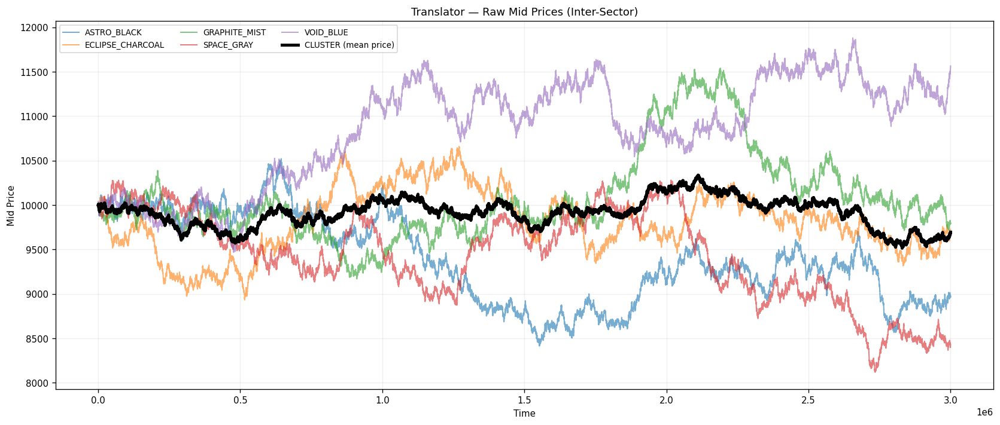

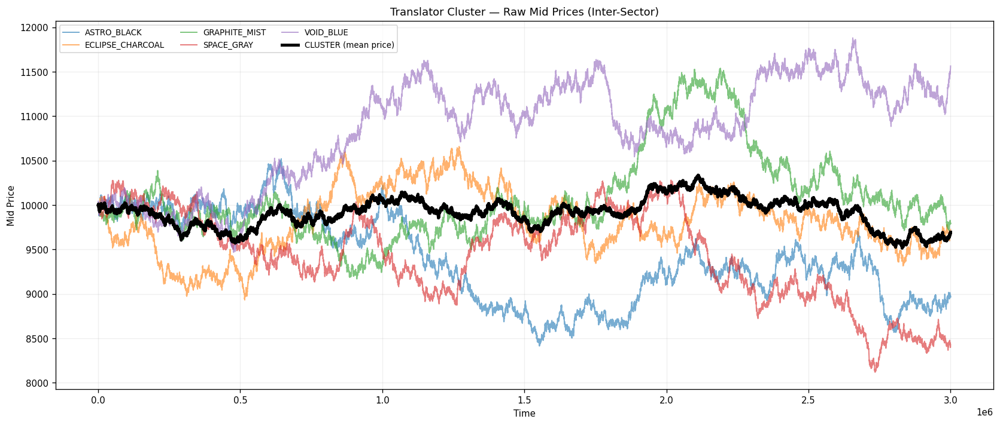

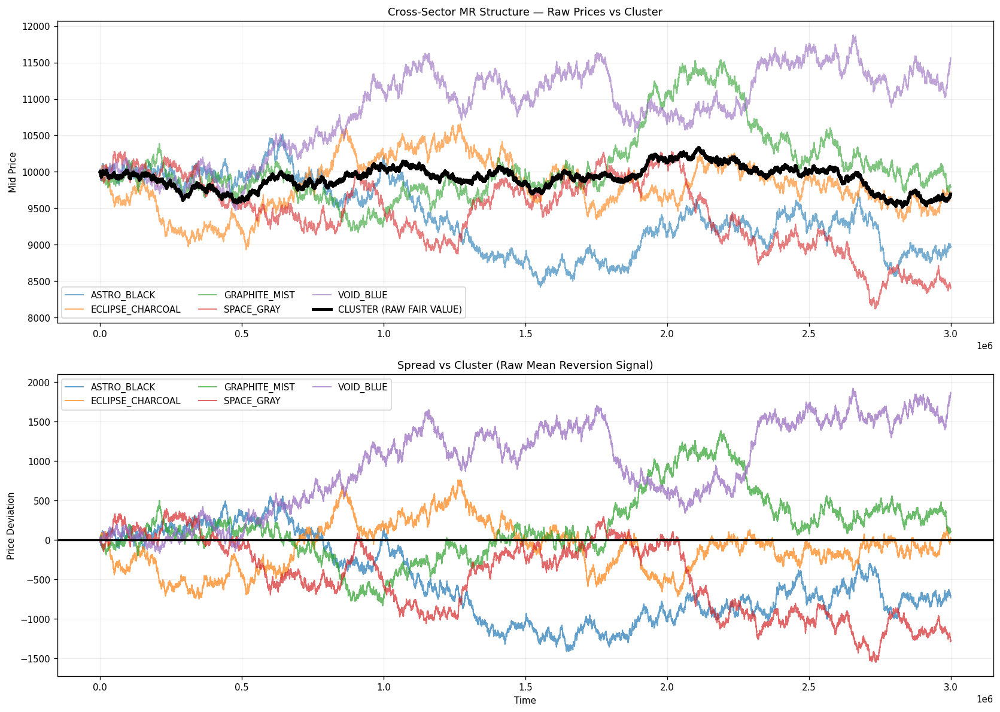

In [92]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


# ─────────────────────────────────────────────
# SAFE MID SERIES (RAW PRICES, KEEP INDEX)
# ─────────────────────────────────────────────
def get_mid_series(product):
    if product not in mid.columns:
        print(f"[WARN] No data for {product}")
        return None

    s = mid[product].dropna()
    if len(s) == 0:
        return None

    return s


# ─────────────────────────────────────────────
# ALIGN ON COMMON TIME INDEX (NO NORMALIZATION)
# ─────────────────────────────────────────────
def align_series(series_dict):
    df = pd.DataFrame(series_dict).dropna()
    return df


# ─────────────────────────────────────────────
# MAIN CLUSTER PLOT (RAW PRICES)
# ─────────────────────────────────────────────
def plot_cluster(products, title="Cluster"):
    series = {}

    for p in products:
        s = get_mid_series(p)
        if s is not None:
            series[p] = s

    if not series:
        print("No valid data found.")
        return

    df = align_series(series)

    cluster = df.mean(axis=1)

    plt.figure(figsize=(14, 6))

    for col in df.columns:
        plt.plot(df.index, df[col], alpha=0.6, linewidth=1.2, label=col.split("_", 1)[-1])

    plt.plot(df.index, cluster, linewidth=3, color="black", label="CLUSTER (mean price)")

    plt.title(f"{title} — Raw Mid Prices (Inter-Sector)")
    plt.xlabel("Time")
    plt.ylabel("Mid Price")
    plt.legend(fontsize=8, ncol=3)
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()


# ─────────────────────────────────────────────
# FAMILY WRAPPER
# ─────────────────────────────────────────────
def plot_family(family_name):
    prods = FAMILIES.get(family_name)
    if prods is None:
        print(f"[WARN] Unknown family '{family_name}'")
        return
    plot_cluster(prods, title=family_name)


# ─────────────────────────────────────────────
# CPS / MR ANALYSIS (RAW PRICES)
# ─────────────────────────────────────────────
def plot_cps_mr_cluster(products, title="Cluster MR Analysis"):
    series = {}

    for p in products:
        s = get_mid_series(p)
        if s is not None:
            series[p] = s

    if not series:
        print("No valid data found.")
        return

    df = align_series(series)

    cluster = df.mean(axis=1)
    spreads = df.subtract(cluster, axis=0)

    fig, axes = plt.subplots(2, 1, figsize=(14, 10))

    # ─────────────────────────────
    # 1. RAW PRICES
    # ─────────────────────────────
    for col in df.columns:
        axes[0].plot(df.index, df[col], alpha=0.6, linewidth=1.2, label=col.split("_", 1)[-1])

    axes[0].plot(df.index, cluster, linewidth=3, color="black", label="CLUSTER (RAW FAIR VALUE)")

    axes[0].set_title(f"{title} — Raw Prices vs Cluster")
    axes[0].set_ylabel("Mid Price")
    axes[0].legend(ncol=3)
    axes[0].grid(alpha=0.2)

    # ─────────────────────────────
    # 2. SPREADS (MEAN REVERSION SIGNAL)
    # ─────────────────────────────
    for col in spreads.columns:
        axes[1].plot(spreads.index, spreads[col], linewidth=1.2, alpha=0.7, label=col.split("_", 1)[-1])

    axes[1].axhline(0, color="black", linewidth=2)

    axes[1].set_title("Spread vs Cluster (Raw Mean Reversion Signal)")
    axes[1].set_ylabel("Price Deviation")
    axes[1].set_xlabel("Time")
    axes[1].legend(ncol=3)
    axes[1].grid(alpha=0.2)

    plt.tight_layout()
    plt.show()


# ─────────────────────────────────────────────
# EXAMPLES
# ─────────────────────────────────────────────

plot_family("Translator")

plot_cluster([
    "TRANSLATOR_ASTRO_BLACK",
    "TRANSLATOR_ECLIPSE_CHARCOAL",
    "TRANSLATOR_GRAPHITE_MIST",
    "TRANSLATOR_SPACE_GRAY",
    "TRANSLATOR_VOID_BLUE"
], title="Translator Cluster")
plot_cps_mr_cluster(["TRANSLATOR_ASTRO_BLACK",
    "TRANSLATOR_ECLIPSE_CHARCOAL",
    "TRANSLATOR_GRAPHITE_MIST",
    "TRANSLATOR_SPACE_GRAY",
    "TRANSLATOR_VOID_BLUE"], title="Cross-Sector MR Structure")

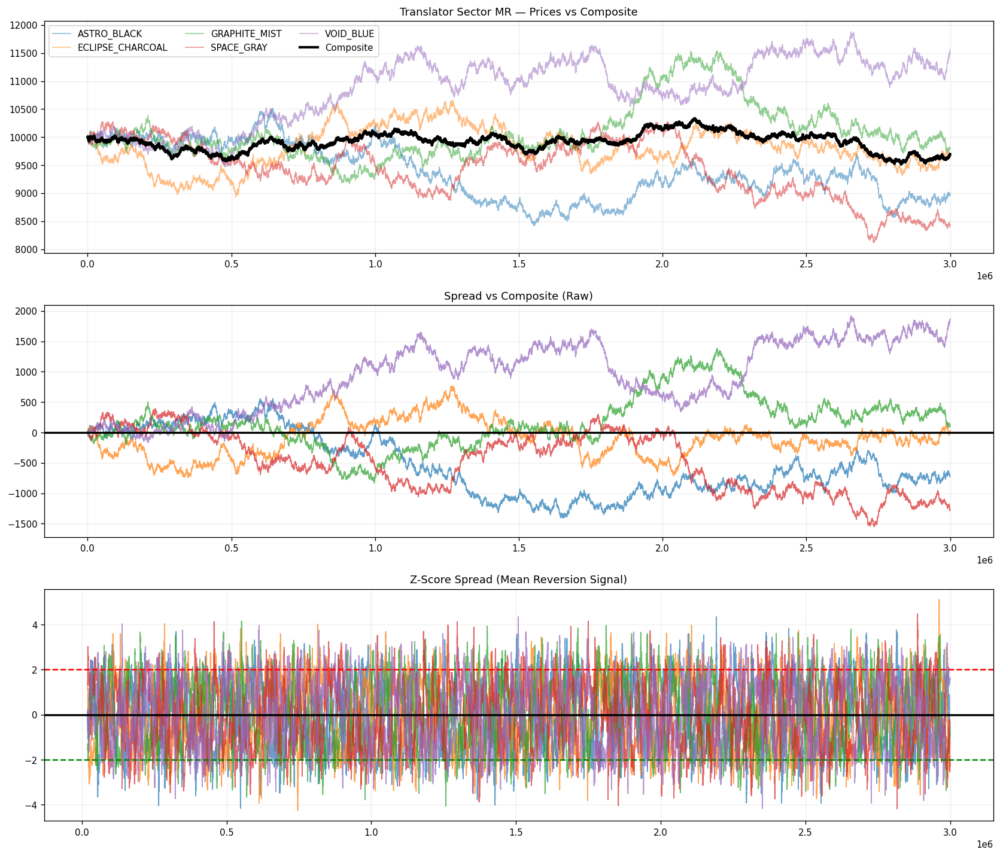

In [93]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def plot_sector_mr(products, title="Sector MR Analysis", window=200):
    series = {}

    # ── load mid prices ─────────────────────────────
    for p in products:
        if p not in mid.columns:
            continue
        s = mid[p].dropna()
        if len(s) > 0:
            series[p] = s

    if not series:
        print("No valid data.")
        return

    # ── align time ─────────────────────────────────
    df = pd.DataFrame(series).dropna()

    # ── composite (sector fair value) ──────────────
    composite = df.mean(axis=1)

    # ── spreads ────────────────────────────────────
    spreads = df.subtract(composite, axis=0)

    # ── rolling z-score (key for MR signal) ────────
    rolling_mean = spreads.rolling(window).mean()
    rolling_std  = spreads.rolling(window).std()

    zscores = (spreads - rolling_mean) / rolling_std

    # ──────────────────────────────────────────────
    # PLOTS
    # ──────────────────────────────────────────────
    fig, axes = plt.subplots(3, 1, figsize=(14, 12))

    # 1. Prices + composite
    for col in df.columns:
        axes[0].plot(df.index, df[col], alpha=0.5, lw=1, label=col.split("_",1)[-1])

    axes[0].plot(df.index, composite, color="black", lw=2.5, label="Composite")
    axes[0].set_title(f"{title} — Prices vs Composite")
    axes[0].legend(ncol=3)
    axes[0].grid(alpha=0.2)

    # 2. Raw spreads
    for col in spreads.columns:
        axes[1].plot(spreads.index, spreads[col], alpha=0.7, lw=1)

    axes[1].axhline(0, color="black", lw=2)
    axes[1].set_title("Spread vs Composite (Raw)")
    axes[1].grid(alpha=0.2)

    # 3. Z-score spreads (THIS is the signal)
    for col in zscores.columns:
        axes[2].plot(zscores.index, zscores[col], alpha=0.7, lw=1)

    axes[2].axhline(2, color="red", ls="--")
    axes[2].axhline(-2, color="green", ls="--")
    axes[2].axhline(0, color="black", lw=2)

    axes[2].set_title("Z-Score Spread (Mean Reversion Signal)")
    axes[2].grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

plot_sector_mr([
    "TRANSLATOR_ASTRO_BLACK",
    "TRANSLATOR_ECLIPSE_CHARCOAL",
    "TRANSLATOR_GRAPHITE_MIST",
    "TRANSLATOR_SPACE_GRAY",
    "TRANSLATOR_VOID_BLUE"
], title="Translator Sector MR")

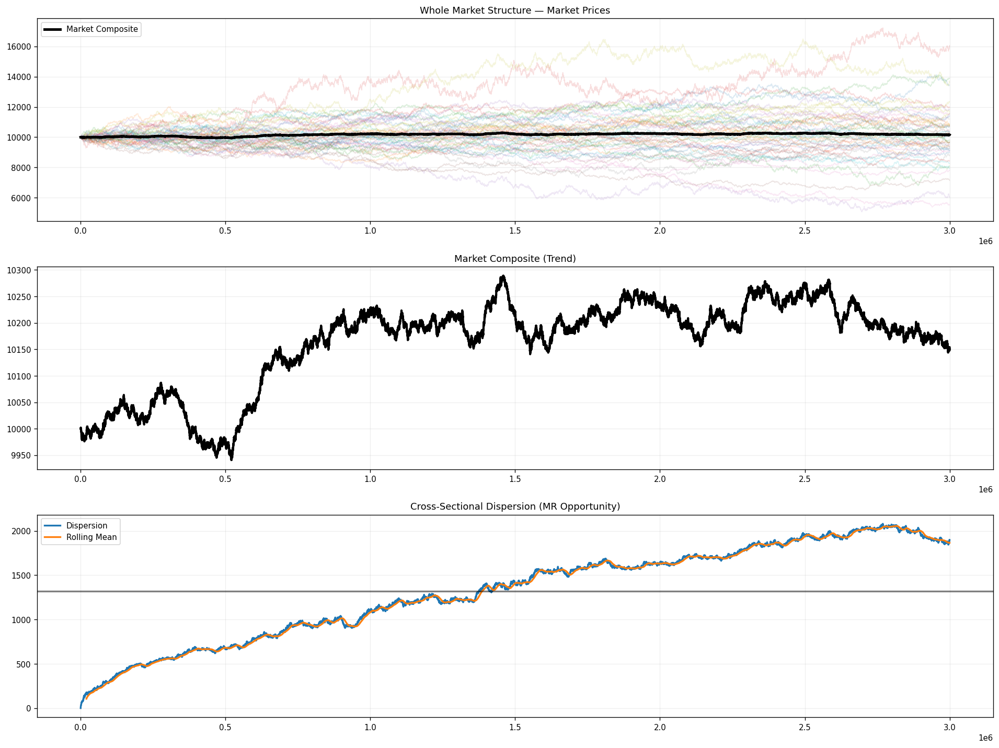

In [94]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def plot_market_overview(title="Whole Market Structure", window=200):
    # ── get all valid products ─────────────────────
    df = mid.copy().dropna(axis=1, how='all')
    df = df.dropna()

    if df.shape[1] == 0:
        print("No valid data.")
        return

    # ── market composite ───────────────────────────
    market = df.mean(axis=1)

    # ── dispersion (cross-sectional std) ───────────
    dispersion = df.std(axis=1)

    # ── z-score dispersion (optional signal) ───────
    disp_mean = dispersion.rolling(window).mean()
    disp_std  = dispersion.rolling(window).std()
    disp_z    = (dispersion - disp_mean) / disp_std

    # ──────────────────────────────────────────────
    # PLOTS
    # ──────────────────────────────────────────────
    fig, axes = plt.subplots(3, 1, figsize=(16, 12))

    # 1. Market + all products
    for col in df.columns:
        axes[0].plot(df.index, df[col], alpha=0.15, lw=0.8)

    axes[0].plot(df.index, market, color="black", lw=3, label="Market Composite")
    axes[0].set_title(f"{title} — Market Prices")
    axes[0].legend()
    axes[0].grid(alpha=0.2)

    # 2. Market only (clean trend view)
    axes[1].plot(df.index, market, color="black", lw=2.5)
    axes[1].set_title("Market Composite (Trend)")
    axes[1].grid(alpha=0.2)

    # 3. Dispersion (THIS tells you if MR works)
    axes[2].plot(df.index, dispersion, lw=2, label="Dispersion")
    axes[2].plot(df.index, disp_mean, lw=2, label="Rolling Mean")
    
    axes[2].axhline(dispersion.mean(), color="black", lw=2, alpha=0.5)

    axes[2].set_title("Cross-Sectional Dispersion (MR Opportunity)")
    axes[2].legend()
    axes[2].grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

plot_market_overview()

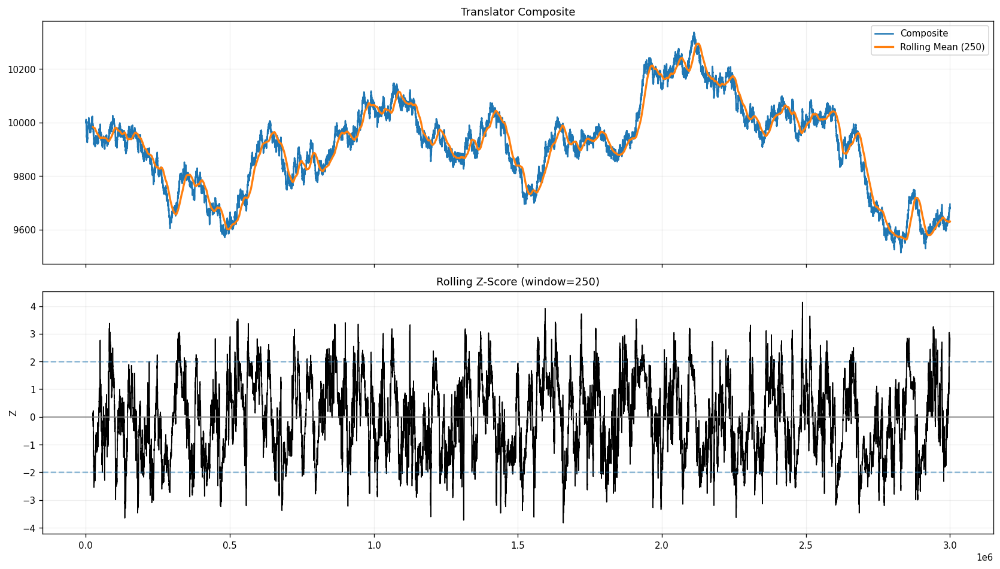

In [111]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def plot_translator_zscore(z_window=1000):
    products = [
        "TRANSLATOR_ASTRO_BLACK",
        "TRANSLATOR_ECLIPSE_CHARCOAL",
        "TRANSLATOR_GRAPHITE_MIST",
        "TRANSLATOR_SPACE_GRAY",
        "TRANSLATOR_VOID_BLUE",
    ]

    series = {}

    # ── load data ─────────────────────────────
    for p in products:
        if p in mid.columns:
            s = mid[p].dropna()
            if len(s) > 0:
                series[p] = s

    if not series:
        print("No data found.")
        return

    # ── align ────────────────────────────────
    df = pd.DataFrame(series).dropna()

    # ── composite price ──────────────────────
    composite = df.mean(axis=1)

    # ── rolling z-score ──────────────────────
    rolling_mean = composite.rolling(z_window).mean()
    rolling_std  = composite.rolling(z_window).std()

    z = (composite - rolling_mean) / rolling_std

    # ── plot ────────────────────────────────
    fig, ax = plt.subplots(2, 1, figsize=(14,8), sharex=True)

    # price
    ax[0].plot(composite.index, composite.values, label="Composite", linewidth=1.5)
    ax[0].plot(rolling_mean.index, rolling_mean.values, label=f"Rolling Mean ({z_window})", linewidth=2)

    ax[0].set_title("Translator Composite")
    ax[0].legend()
    ax[0].grid(alpha=0.2)

    # z-score
    ax[1].plot(z.index, z.values, color="black", linewidth=1)
    ax[1].axhline(0, color="gray", linewidth=1)
    ax[1].axhline(2, linestyle="--", alpha=0.5)
    ax[1].axhline(-2, linestyle="--", alpha=0.5)

    ax[1].set_title(f"Rolling Z-Score (window={z_window})")
    ax[1].set_ylabel("Z")
    ax[1].grid(alpha=0.2)

    plt.tight_layout()
    plt.show()


# run
plot_translator_zscore(z_window=250)

In [ ]:

# ── ORANGE → MAGENTA lag strategy proof (returns-based) ──────────────────────
LAG       = 150
THRESHOLD = 25
SIZE      = 10

orange  = mid["UV_VISOR_ORANGE"].dropna().values
magenta = mid["UV_VISOR_MAGENTA"].dropna().values
n = min(len(orange), len(magenta))
orange, magenta = orange[:n], magenta[:n]

# Use first differences (returns) — removes common trend
orn_ret = np.diff(orange)
mag_ret = np.diff(magenta)
nr = len(orn_ret)

# ── Cross-correlation on RETURNS ──────────────────────────────────────────────
max_lag = 300
lags_range = list(range(-max_lag, max_lag + 1))
xcorr = []
for lag in lags_range:
    if lag < 0:
        xs, ys = orn_ret[-lag:], mag_ret[:nr + lag]
    elif lag > 0:
        xs, ys = orn_ret[:-lag], mag_ret[lag:]
    else:
        xs, ys = orn_ret, mag_ret
    xcorr.append(np.corrcoef(xs, ys)[0, 1])
xcorr    = np.array(xcorr)
peak_idx = np.argmax(np.abs(xcorr))
peak_lag = lags_range[peak_idx]
peak_cor = xcorr[peak_idx]

# ── Predictive scatter: ORANGE past LAG-tick return vs MAGENTA next LAG-tick return
signal_rets, mag_fwd_rets = [], []
for t in range(LAG, n - LAG):
    sig = orange[t] - orange[t - LAG]
    fwd = magenta[t + LAG] - magenta[t]
    signal_rets.append(sig)
    mag_fwd_rets.append(fwd)
signal_rets  = np.array(signal_rets)
mag_fwd_rets = np.array(mag_fwd_rets)
m, b = np.polyfit(signal_rets, mag_fwd_rets, 1)

# ── Simulated PnL ─────────────────────────────────────────────────────────────
pnl, cum, pos = [], [], 0
for t in range(1, n):
    pnl_tick = pos * (magenta[t] - magenta[t - 1])
    pnl.append(pnl_tick)
    cum.append((cum[-1] if cum else 0) + pnl_tick)
    if t >= LAG:
        delta = orange[t] - orange[t - LAG]
        pos = SIZE if delta > THRESHOLD else (-SIZE if delta < -THRESHOLD else 0)
pnl = np.array(pnl)
cum = np.array(cum)

# ── Plots ─────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].plot(lags_range, xcorr, linewidth=0.9, color='steelblue')
axes[0].axvline(peak_lag, color='red', linestyle='--', linewidth=1.2,
                label=f'peak lag={peak_lag}, corr={peak_cor:.3f}')
axes[0].axhline(0, color='black', linewidth=0.7)
conf = 1.96 / np.sqrt(nr)
axes[0].axhline(conf,  color='grey', linestyle=':', linewidth=0.8, label='95% CI')
axes[0].axhline(-conf, color='grey', linestyle=':', linewidth=0.8)
axes[0].set_xlabel('Lag (ticks)  [negative = ORANGE leads MAGENTA]')
axes[0].set_ylabel('Cross-correlation of RETURNS')
axes[0].set_title('Cross-correlation on RETURNS\n(removes common trend — true lead-lag test)',
                  fontweight='bold')
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.2)

axes[1].scatter(signal_rets, mag_fwd_rets, alpha=0.05, s=4, color='navy')
x_line = np.linspace(signal_rets.min(), signal_rets.max(), 200)
axes[1].plot(x_line, m * x_line + b, color='red', linewidth=1.5,
             label=f'slope={m:.4f}')
axes[1].axhline(0, color='black', linewidth=0.7)
axes[1].axvline(0, color='black', linewidth=0.7)
axes[1].set_xlabel(f'ORANGE return over past {LAG} ticks')
axes[1].set_ylabel(f'MAGENTA return over next {LAG} ticks')
axes[1].set_title('Predictive scatter\n(positive slope = edge exists)',
                  fontweight='bold')
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.2)

axes[2].plot(cum, linewidth=1.0, color='green')
axes[2].axhline(0, color='black', linewidth=0.7)
axes[2].set_xlabel('Tick')
axes[2].set_ylabel('Cumulative PnL')
sharpe = pnl.mean() / pnl.std() * np.sqrt(10000) if pnl.std() > 0 else 0
axes[2].set_title(f'Simulated PnL | threshold={THRESHOLD}, size={SIZE}\n'
                  f'Total={cum[-1]:,.0f}   Sharpe≈{sharpe:.2f}',
                  fontweight='bold')
axes[2].grid(True, alpha=0.2)

plt.suptitle('ORANGE → MAGENTA Lag Strategy Proof (returns-based)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Peak cross-correlation (returns): lag={peak_lag}, corr={peak_cor:.4f}")
print(f"95% CI threshold: ±{conf:.4f}")
print(f"Predictive slope: {m:.4f}  {'POSITIVE — edge exists' if m > 0 else 'NEGATIVE — no edge / wrong direction'}")
print(f"Total PnL: {cum[-1]:,.0f}   Sharpe: {sharpe:.2f}")


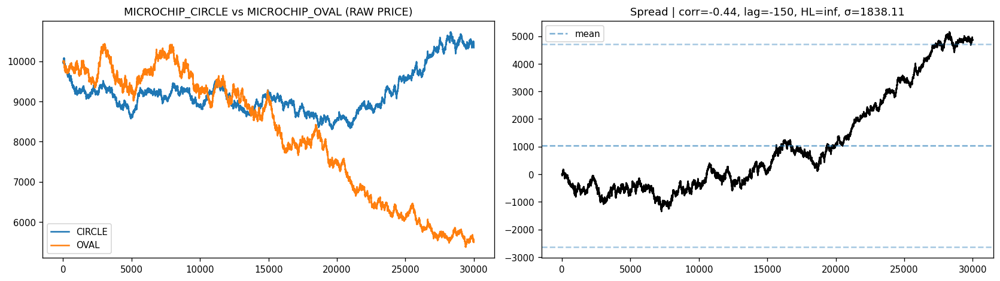

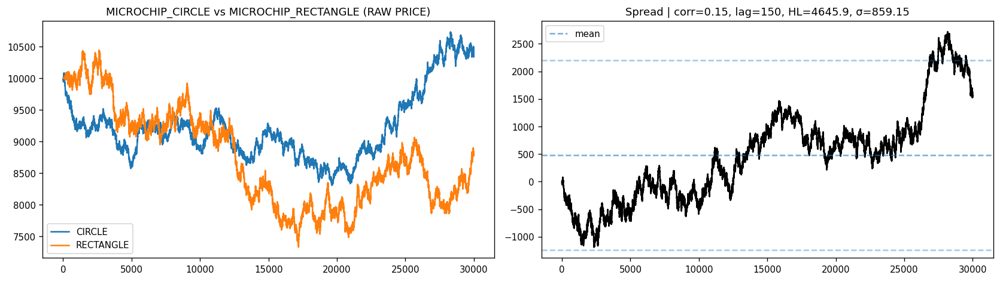

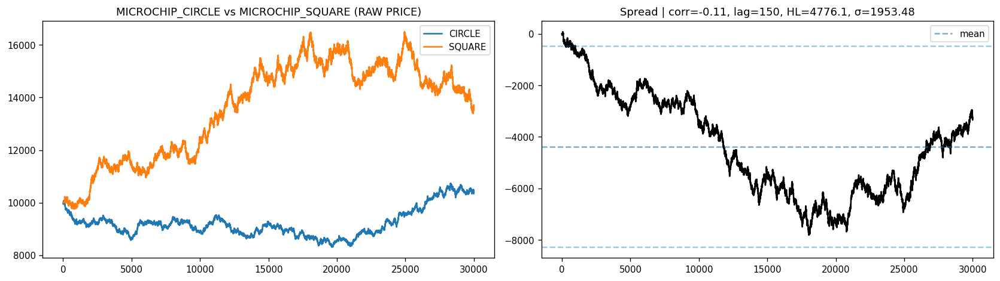

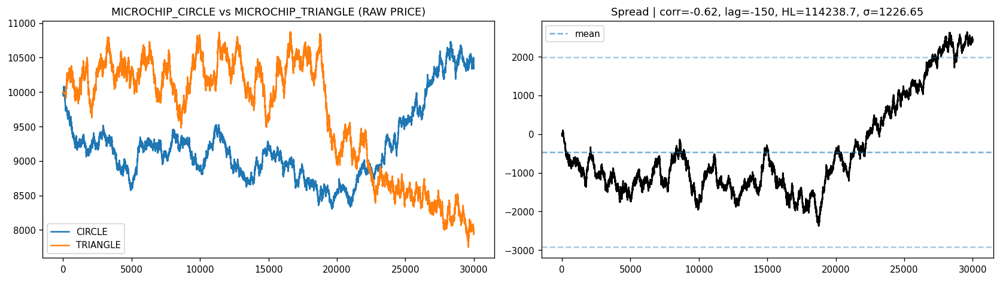

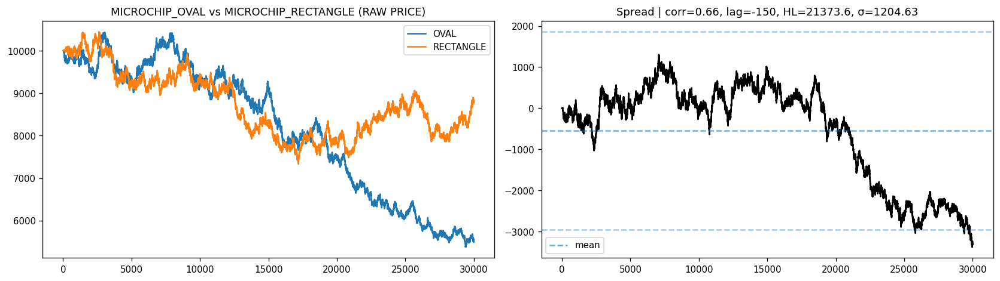

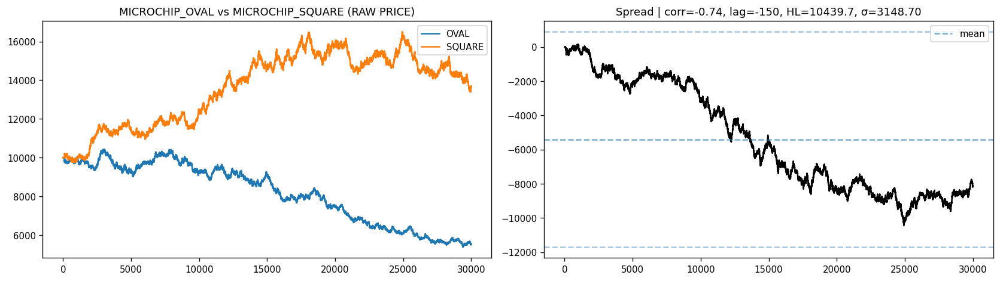

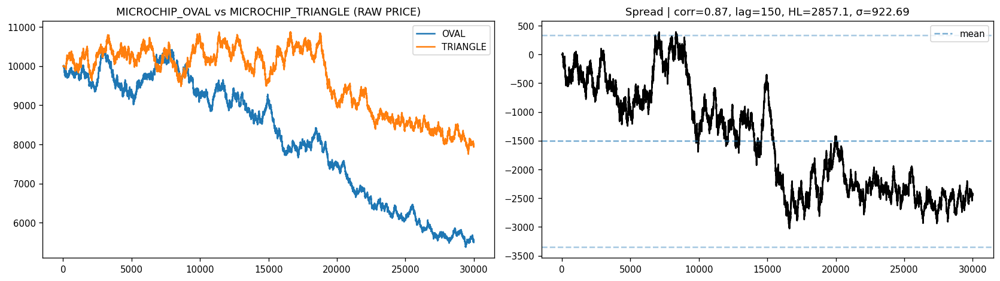

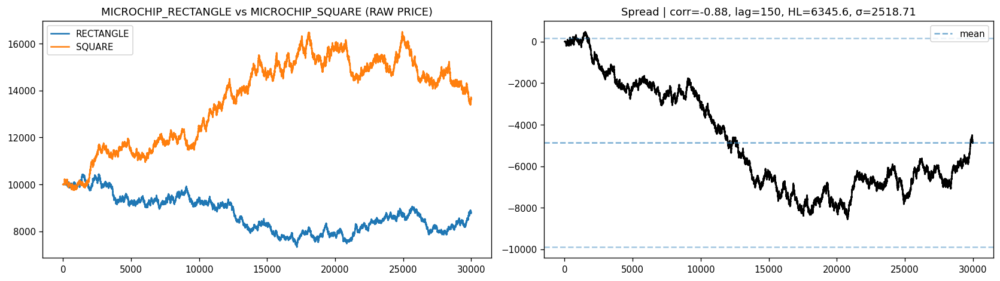

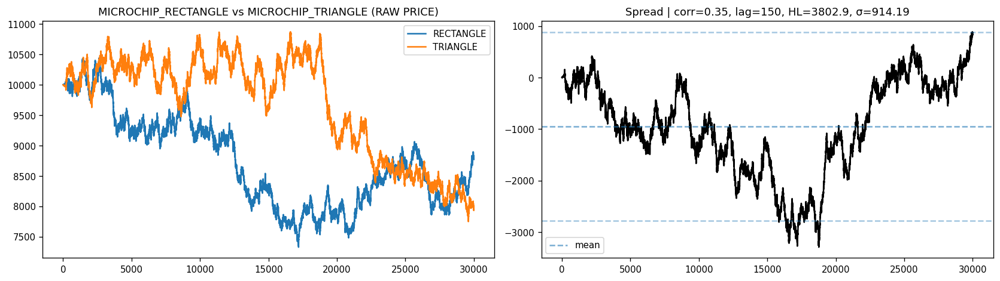

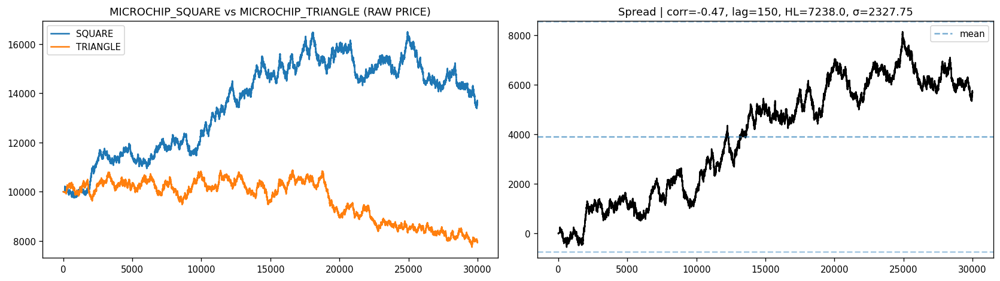


Top pairs (RAW spread MR strength):

MICROCHIP_OVAL vs MICROCHIP_TRIANGLE | corr=0.87, lag=150, HL=2857.1, mean=-1506.79, σ=922.69
MICROCHIP_RECTANGLE vs MICROCHIP_TRIANGLE | corr=0.35, lag=150, HL=3802.9, mean=-953.95, σ=914.19
MICROCHIP_CIRCLE vs MICROCHIP_RECTANGLE | corr=0.15, lag=150, HL=4645.9, mean=482.45, σ=859.15
MICROCHIP_CIRCLE vs MICROCHIP_SQUARE | corr=-0.11, lag=150, HL=4776.1, mean=-4379.86, σ=1953.48
MICROCHIP_RECTANGLE vs MICROCHIP_SQUARE | corr=-0.88, lag=150, HL=6345.6, mean=-4862.31, σ=2518.71
MICROCHIP_SQUARE vs MICROCHIP_TRIANGLE | corr=-0.47, lag=150, HL=7238.0, mean=3908.36, σ=2327.75
MICROCHIP_OVAL vs MICROCHIP_SQUARE | corr=-0.74, lag=-150, HL=10439.7, mean=-5415.15, σ=3148.70
MICROCHIP_OVAL vs MICROCHIP_RECTANGLE | corr=0.66, lag=-150, HL=21373.6, mean=-552.84, σ=1204.63
MICROCHIP_CIRCLE vs MICROCHIP_TRIANGLE | corr=-0.62, lag=-150, HL=114238.7, mean=-471.51, σ=1226.65
MICROCHIP_CIRCLE vs MICROCHIP_OVAL | corr=-0.44, lag=-150, HL=inf, mean=1035.29, σ=1838.11

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations

# ── Lag correlation on raw prices ──────────────────────────────────────────
def best_lag_corr_raw(x, y, max_lag=150):
    best_corr = 0
    best_lag = 0

    for lag in range(-max_lag, max_lag + 1):
        if lag < 0:
            xs = x[-lag:]
            ys = y[:len(y)+lag]
        elif lag > 0:
            xs = x[:-lag]
            ys = y[lag:]
        else:
            xs, ys = x, y

        if len(xs) < 100:
            continue

        corr = np.corrcoef(xs, ys)[0,1]
        if abs(corr) > abs(best_corr):
            best_corr = corr
            best_lag = lag

    return best_lag, best_corr


# ── Half-life using RAW spread ─────────────────────────────────────────────
def half_life_raw(spread):
    spread_lag = spread[:-1]
    spread_ret = spread[1:] - spread[:-1]

    beta = np.polyfit(spread_lag, spread_ret, 1)[0]
    if beta >= 0:
        return np.inf

    return -np.log(2) / beta


# ── MAIN ANALYSIS (FULL RAW) ───────────────────────────────────────────────
def analyze_microchip_pairs_raw():
    products = FAMILIES['Microchip']
    results = []

    for a, b in combinations(products, 2):
        x = get_mid_series(a)
        y = get_mid_series(b)

        if x is None or y is None:
            continue

        n = min(len(x), len(y))
        x, y = x[:n], y[:n]

        spread = x - y

        lag, corr = best_lag_corr_raw(x, y)
        hl = half_life_raw(spread)

        mean_spread = np.mean(spread)
        std_spread = np.std(spread)

        results.append((a, b, corr, lag, hl, mean_spread, std_spread))

        # ── Plot ─────────────────────────────────────
        fig, axes = plt.subplots(1, 2, figsize=(14,4))

        # RAW PRICE OVERLAY
        axes[0].plot(x, label=a.split('_')[-1])
        axes[0].plot(y, label=b.split('_')[-1])
        axes[0].set_title(f"{a} vs {b} (RAW PRICE)")
        axes[0].legend()

        # RAW SPREAD (NO NORMALIZATION)
        axes[1].plot(spread, color='black')
        axes[1].axhline(mean_spread, linestyle='--', alpha=0.6, label='mean')

        # optional: 2-sigma bands (REAL thresholds)
        axes[1].axhline(mean_spread + 2*std_spread, linestyle='--', alpha=0.4)
        axes[1].axhline(mean_spread - 2*std_spread, linestyle='--', alpha=0.4)

        axes[1].set_title(
            f"Spread | corr={corr:.2f}, lag={lag}, HL={hl:.1f}, σ={std_spread:.2f}"
        )
        axes[1].legend()

        plt.tight_layout()
        plt.show()

    # ── Ranking ─────────────────────────────────────
    results = sorted(results, key=lambda x: (x[4], -abs(x[2])))

    print("\nTop pairs (RAW spread MR strength):\n")
    for r in results[:10]:
        print(
            f"{r[0]} vs {r[1]} | corr={r[2]:.2f}, lag={r[3]}, HL={r[4]:.1f}, "
            f"mean={r[5]:.2f}, σ={r[6]:.2f}"
        )
analyze_microchip_pairs_raw()